# A Hierarchical LLM Workflow for Detecting Colonial Propaganda in the French Press

## License and citation

This notebook accompanies the following published abstract:

*   Affan, Ferdaous (2026): “A Hierarchical LLM Workflow for Detecting Colonial Propaganda in Historical Newspapers: the Case of the Perdicaris Affair (1904)”, *in: Digital Humanities 2026: Book of Abstracts? 501-504*. ADHO Digital Humanities Conference 2026 (DH2026), Daejeon Convention Center. DOI: 10.5281/zenodo.21495909.

The DOI identifies the complete DH2026 Book of Abstracts.

When using this workflow, please use the citation above.


The software code in this notebook is licensed under the GNU General Public License v3.0.

Original explanatory text, prompts, and figures are licensed under the Creative Commons Attribution–NonCommercial 4.0 International Licence unless otherwise indicated.

Third-party newspaper material and Impresso-derived source content are excluded from these licences and remain subject to their original rights and access conditions.










## Perdicaris Affair Corpus (1904) - DH2026

This notebook implements a **4-stage pipeline** for detecting and analyzing colonial propaganda in historical newspaper articles.

### Framework Architecture
- **Level 1: Ideological Frames** (3) - Legitimization, Demonization, Naturalization
- **Level 2: Rhetorical Mechanisms** (9) - Three per frame
- **Level 3: Historical Tropes** - Period-specific vocabulary

### Pipeline Stages
1. **Initial Detection & Relevance** - Binary classification + relevance to Perdicaris/Morocco
2. **Intensity Assessment** - Density, Explicitness, Emotional Impact
3. **Frame & Mechanism Identification** - Hierarchical taxonomy classification
4. **Trope Extraction & Contextual Analysis** - Historical vocabulary and rhetorical context

### Corpus Metadata Fields
- `id`, `title`, `date`, `year`, `text`, `textLength`
- `countryCode`, `languageCode`, `source`
- `mediaPoliticalOrientation`, `mediaTopics`
- `issue`, `pages`, `isOnFrontPage`

## 1. Setup and Configuration

In [ ]:
import openai
from openai import OpenAI
import pandas as pd
import json
from datetime import datetime
from typing import Dict, List, Optional, Tuple, Any
import time
import os
from IPython.display import display, HTML
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("husl")

print("✓ Imports complete")

✓ Imports complete


In [ ]:
# Configure API key
import os

api_key = os.getenv("OPENAI_API_KEY")

if not api_key:
    raise ValueError(
        "Set the OPENAI_API_KEY environment variable before running the notebook."
    )

✓ OpenAI API key configured


## 2. Hierarchical Taxonomy Definition

In [ ]:
TAXONOMY = {
    "Legitimization": {
        "description": "Discourse that produces consent for colonial intervention, presence, or policy.",
        "mechanisms": [
            {"id": 1, "name": "Authority Appeal", "subtypes": ["Expert", "Institutional", "Legal", "Scientific", "Eyewitness"]},
            {"id": 2, "name": "Value/Duty Appeal", "subtypes": ["Civilizing Duty", "Humanitarian", "Religious", "National Honor", "Historical Destiny"]},
            {"id": 3, "name": "Exemplification", "subtypes": ["Explorer/Discoverer", "Administrator/Pacifier", "Soldier/Conqueror", "Missionary/Educator", "Settler/Pioneer"]}
        ]
    },
    "Demonization": {
        "description": "Discourse that constructs threats, enemies, or dangers requiring response.",
        "mechanisms": [
            {"id": 4, "name": "Fear Appeal", "subtypes": ["Physical Danger", "Property Threat", "Order Threat", "Contagion Threat", "Honor/Prestige Threat"]},
            {"id": 5, "name": "Labeling", "subtypes": ["Criminal", "Religious", "Savage/Primitive", "Animal/Subhuman", "Political"]},
            {"id": 6, "name": "State Failure Framing", "subtypes": ["Governance Failure", "Security Failure", "Sovereignty Failure", "Modernization Failure", "Diplomatic Failure"]}
        ]
    },
    "Naturalization": {
        "description": "Discourse that presents colonial hierarchy as natural, inevitable, or beyond question.",
        "mechanisms": [
            {"id": 7, "name": "Essentialization", "subtypes": ["Racial", "Cultural", "Psychological", "Temporal", "Comparative"]},
            {"id": 8, "name": "Normalization", "subtypes": ["Consensus", "Inevitability", "Precedent", "Comparison", "Definitional"]},
            {"id": 9, "name": "Selective Framing", "subtypes": ["Selective Evidence", "Selective Sourcing", "Selective Context", "Selective Attribution", "Selective Silence"]}
        ]
    }
}

HISTORICAL_TROPES = {
    "Legitimization": {
        "fr": ["mission civilisatrice", "pénétration pacifique", "mise en valeur", "protectorat", "droits acquis", "intérêts français", "ordre", "paix française"],
        "de": ["Zivilisierungsmission", "friedliche Durchdringung", "Erschließung", "Protektorat", "erworbene Rechte", "Ordnung"]
    },
    "Demonization": {
        "fr": ["brigand", "bandit", "chef de bande", "Raissouli", "Raisuli", "fanatique", "anarchie marocaine", "Makhzen impuissant", "désordre", "pillage", "razzia", "enlèvement"],
        "de": ["Räuber", "Bandit", "Bandenchef", "Raisuli", "Fanatiker", "marokkanische Anarchie", "Entführung"]
    },
    "Naturalization": {
        "fr": ["race arabe", "race berbère", "l'âme marocaine", "mentalité indigène", "fatalisme oriental", "indolence", "moyen âge", "arriéré", "primitif"],
        "de": ["arabische Rasse", "marokkanische Seele", "eingeborene Mentalität", "orientalischer Fatalismus", "rückständig", "primitiv"]
    }
}

print(f"✓ Taxonomy loaded: 3 frames, 9 mechanisms")

✓ Taxonomy loaded: 3 frames, 9 mechanisms


## 3. System Prompt

In [ ]:
SYSTEM_PROMPT = """You are a specialized propaganda detection model trained in colonial discourse analysis (1880-1914).

**MULTILINGUAL INSTRUCTIONS:**
- Articles may be in FRENCH or GERMAN
- ALWAYS quote evidence in the ORIGINAL LANGUAGE (never translate)

**HISTORICAL CONTEXT: THE PERDICARIS AFFAIR (1904)**
On May 18, 1904, Mulai Ahmed er Raisuni kidnapped Ion Perdicaris, a Greek-American businessman, near Tangier.
The crisis lasted until June 24, 1904, generating intensive press coverage with systematic colonial propaganda.

## THREE-LEVEL TAXONOMY

### LEVEL 1: IDEOLOGICAL FRAMES
- **LEGITIMIZATION**: Produces consent for colonial intervention (Authority Appeal, Value/Duty Appeal, Exemplification)
- **DEMONIZATION**: Constructs threats requiring response (Fear Appeal, Labeling, State Failure Framing)
- **NATURALIZATION**: Makes hierarchy seem inevitable (Essentialization, Normalization, Selective Framing)

### LEVEL 2: MECHANISMS (9 total)
1. Authority Appeal - Invoking expertise, institutions, legal frameworks
2. Value/Duty Appeal - Framing action as moral obligation, civilizing mission
3. Exemplification - Constructing admirable colonial figures
4. Fear Appeal - Constructing threats to persons, property, order
5. Labeling - Assigning evaluative identity (brigand, savage, fanatic)
6. State Failure Framing - Constructing target state as incapable of governing
7. Essentialization - Attributing fixed characteristics to groups
8. Normalization - Presenting contingent as natural/inevitable
9. Selective Framing - Controlling inclusion/exclusion of information

### LEVEL 3: HISTORICAL TROPES
- Legitimization: mission civilisatrice, protectorat, droits acquis, pénétration pacifique
- Demonization: brigand, bandit, anarchie marocaine, Makhzen impuissant, fanatique
- Naturalization: race arabe/berbère, mentalité indigène, arriéré, primitif

## DETECTION GUIDELINES
- Multiple frames/mechanisms may co-occur
- Every claim needs verbatim evidence in original language
- Confidence: HIGH (80-100%), MEDIUM (50-79%), LOW (20-49%)
- Note absence of Moroccan voice as Selective Framing
"""

print(f"✓ System prompt ready ({len(SYSTEM_PROMPT)} chars)")

✓ System prompt ready (2088 chars)


## 4. Core Functions

In [ ]:
def call_openai(messages: List[Dict], model: str = "gpt-4o", temperature: float = 0.2, max_retries: int = 3) -> Dict:
    """Call OpenAI API with JSON response format and retry logic."""
    for attempt in range(max_retries):
        try:
            resp = client.chat.completions.create(
                model=model,
                messages=messages,
                temperature=temperature,
                response_format={"type": "json_object"},
            )
            content = resp.choices[0].message.content
            return json.loads(content) if content else {}
        except Exception as e:
            if attempt < max_retries - 1:
                time.sleep(2 ** attempt)
                continue
            raise Exception(f"OpenAI API Error: {e}")

def detect_language(text: str) -> str:
    """Detect French vs German."""
    german = ['der', 'die', 'das', 'und', 'ist', 'von', 'mit', 'für', 'auf', 'den', 'dem', 'wurde', 'werden']
    french = ['le', 'la', 'les', 'de', 'du', 'des', 'et', 'est', 'que', 'qui', 'dans', 'pour', 'sur', 'avec']
    words = text.lower().split()
    return 'de' if sum(w in german for w in words) > sum(w in french for w in words) else 'fr'

print("✓ Core functions defined")

✓ Core functions defined


In [ ]:
def analyze_article(text: str, title: str = "Untitled", metadata: Optional[Dict] = None, model: str = "gpt-4o") -> Dict:
    """
    Analyze a single article using 4-stage pipeline.

    Metadata fields supported:
        id, title, date, year, textLength, countryCode, languageCode, source,
        mediaPoliticalOrientation, mediaTopics, issue, pages, isOnFrontPage
    """
    if metadata is None:
        metadata = {}

    # Use provided languageCode or detect
    language = metadata.get('languageCode', detect_language(text))
    metadata['detected_language'] = language
    lang_name = 'German' if language == 'de' else 'French'

    start_time = time.time()
    api_calls = 0

    print(f"\nAnalyzing: {title[:60]}{'...' if len(title) > 60 else ''}")
    print(f"Source: {metadata.get('source', 'N/A')} | Date: {metadata.get('date', 'N/A')} | Language: {lang_name}")
    print("-" * 70)

    # ═══════════════════════════════════════════════════════════════════
    # STAGE 1: Initial Detection + Relevance Classification
    # ═══════════════════════════════════════════════════════════════════
    print("Stage 1/4: Detection & Relevance...")

    detection = call_openai(
        messages=[
            {"role": "system", "content": SYSTEM_PROMPT},
            {"role": "user", "content": f"""Analyze this article for colonial propaganda AND assess its relevance to the Perdicaris Affair.

Respond in JSON:
{{
  "is_propaganda": boolean,
  "confidence": number (0-100),
  "preliminary_reasoning": "Brief explanation of detection decision",
  "detected_frames": ["list of frames if propaganda detected"],
  "relevance": {{
    "about_perdicaris": boolean,
    "about_morocco": boolean,
    "relevance_category": "CORE" | "RELATED" | "PERIPHERAL" | "UNRELATED",
    "relevance_note": "Explanation of how article relates to Perdicaris Affair / Morocco"
  }}
}}

RELEVANCE CATEGORIES:
- CORE: Directly about Perdicaris kidnapping, Raisuli, immediate diplomatic crisis
- RELATED: About Morocco/Moroccan affairs but not specifically Perdicaris (French interests, Makhzen, other incidents)
- PERIPHERAL: Mentions Morocco/Perdicaris tangentially, or broader colonial context (North Africa, imperial competition)
- UNRELATED: Not about Morocco or colonial affairs (may be misclassified in corpus)

ARTICLE ({lang_name}):
{text}"""}
        ],
        model=model
    )
    api_calls += 1

    relevance = detection.get("relevance", {})
    rel_cat = relevance.get("relevance_category", "UNKNOWN")

    # Build base result with all metadata
    base_result = {
        "id": metadata.get("id", ""),
        "title": title,
        "date": metadata.get("date", ""),
        "year": metadata.get("year", ""),
        "textLength": metadata.get("textLength", len(text)),
        "countryCode": metadata.get("countryCode", ""),
        "languageCode": language,
        "source": metadata.get("source", ""),
        "mediaPoliticalOrientation": metadata.get("mediaPoliticalOrientation", ""),
        "mediaTopics": metadata.get("mediaTopics", ""),
        "issue": metadata.get("issue", ""),
        "pages": metadata.get("pages", ""),
        "isOnFrontPage": metadata.get("isOnFrontPage", False),
        "model": model,
        "relevance": {
            "aboutPerdicaris": relevance.get("about_perdicaris", False),
            "aboutMorocco": relevance.get("about_morocco", False),
            "category": rel_cat,
            "note": relevance.get("relevance_note", "")
        }
    }

    # Early exit if no propaganda
    if not detection.get("is_propaganda", False):
        elapsed = time.time() - start_time
        print(f"→ NO PROPAGANDA | Relevance: {rel_cat}")
        return {
            **base_result,
            "isPropaganda": False,
            "confidence": detection.get("confidence", 0),
            "reasoning": detection.get("preliminary_reasoning", ""),
            "performance": {"timeMs": int(elapsed * 1000), "apiCalls": api_calls}
        }

    # ═══════════════════════════════════════════════════════════════════
    # STAGE 2: Intensity Assessment
    # ═══════════════════════════════════════════════════════════════════
    print("Stage 2/4: Intensity Assessment...")

    intensity = call_openai(
        messages=[
            {"role": "system", "content": SYSTEM_PROMPT},
            {"role": "user", "content": f"""Assess propaganda intensity across THREE dimensions.

Respond in JSON:
{{
  "density_score": number (1-10),
  "explicitness_score": number (1-10),
  "emotional_impact_score": number (1-10),
  "intensity_score": number (average, 1 decimal),
  "intensity_level": "Weak" | "Moderate" | "Strong",
  "justification": "Structure EXACTLY as:

**Density Score (X):** [Explain mechanisms present, cite examples in quotes, justify score.]

**Explicitness Score (X):** [Explain how overt vs implicit. Cite phrases. Note euphemisms or naked assertions.]

**Emotional Impact Score (X):** [Describe tone. Cite inflammatory or restrained language. Justify score.]"
}}

DIMENSIONS:
A. DENSITY (1-10): 1-3 = 1-2 mechanisms | 4-6 = 3-4 mechanisms | 7-10 = 5+ mechanisms
B. EXPLICITNESS (1-10): 1-3 = implicit/euphemistic | 4-6 = mixed | 7-10 = explicit assertions
C. EMOTIONAL IMPACT (1-10): 1-3 = factual | 4-6 = moderate appeals | 7-10 = inflammatory

LEVELS: Weak (1-3.9) | Moderate (4-6.9) | Strong (7-10)

ARTICLE:
{text}"""}
        ],
        model=model
    )
    api_calls += 1

    # ═══════════════════════════════════════════════════════════════════
    # STAGE 3: Frame & Mechanism Identification
    # ═══════════════════════════════════════════════════════════════════
    print("Stage 3/4: Mechanisms...")

    mechanisms_result = call_openai(
        messages=[
            {"role": "system", "content": SYSTEM_PROMPT},
            {"role": "user", "content": f"""Identify all propaganda FRAMES and MECHANISMS.

Respond in JSON:
{{
  "frames": {{"legitimization": bool, "demonization": bool, "naturalization": bool}},
  "mechanisms": [
    {{
      "frame": "Legitimization" | "Demonization" | "Naturalization",
      "mechanism_id": number (1-9),
      "mechanism_name": "name",
      "confidence": number (0-100),
      "spans": [{{"text": "VERBATIM quote in ORIGINAL LANGUAGE", "explanation": "why this demonstrates mechanism"}}],
      "subtype": "specific subtype if identifiable",
      "function_explanation": "why this mechanism serves this frame"
    }}
  ]
}}

MECHANISMS: 1-Authority Appeal, 2-Value/Duty Appeal, 3-Exemplification, 4-Fear Appeal, 5-Labeling, 6-State Failure Framing, 7-Essentialization, 8-Normalization, 9-Selective Framing

ARTICLE:
{text}"""}
        ],
        model=model
    )
    api_calls += 1

    # ═══════════════════════════════════════════════════════════════════
    # STAGE 4: Trope Extraction & Context
    # ═══════════════════════════════════════════════════════════════════
    print("Stage 4/4: Tropes & Context...")

    context_result = call_openai(
        messages=[
            {"role": "system", "content": SYSTEM_PROMPT},
            {"role": "user", "content": f"""Extract HISTORICAL TROPES and provide contextual analysis.

Respond in JSON:
{{
  "tropes": [
    {{"term": "exact term in ORIGINAL LANGUAGE", "frame": "frame", "linked_mechanisms": [ids], "context_in_text": "phrase showing usage"}}
  ],
  "context": {{
    "historical_context": "How does this relate to Perdicaris Affair, Morocco 1904, colonial dynamics?",
    "rhetorical_strategy": "Overall persuasive approach? How do mechanisms work together?",
    "target_audience": "Intended readership? Assumptions about readers?",
    "ideological_framework": "Underlying worldview about colonialism, civilization, Morocco?"
  }}
}}

ARTICLE:
{text}"""}
        ],
        model=model
    )
    api_calls += 1

    # Compile results
    elapsed = time.time() - start_time

    print(f"→ PROPAGANDA | Intensity: {intensity.get('intensity_level', 'N/A')} ({intensity.get('intensity_score', 0)}/10) | Relevance: {rel_cat}")
    print(f"  Mechanisms: {len(mechanisms_result.get('mechanisms', []))} | Tropes: {len(context_result.get('tropes', []))} | Time: {elapsed:.1f}s")

    return {
        **base_result,
        "isPropaganda": True,
        "confidence": detection.get("confidence", 0),
        "intensity": intensity.get("intensity_score", 0),
        "intensityLevel": intensity.get("intensity_level", "N/A"),
        "densityScore": intensity.get("density_score", 0),
        "explicitnessScore": intensity.get("explicitness_score", 0),
        "emotionalImpactScore": intensity.get("emotional_impact_score", 0),
        "intensityJustification": intensity.get("justification", ""),
        "frames": mechanisms_result.get("frames", {}),
        "strategies": mechanisms_result.get("mechanisms", []),
        "tropes": context_result.get("tropes", []),
        "context": context_result.get("context", {}),
        "performance": {"timeMs": int(elapsed * 1000), "apiCalls": api_calls}
    }

print("✓ Main analysis function defined")

✓ Main analysis function defined


## 5. Batch Processing

In [ ]:
def analyze_batch_from_json(
    filepath: str,
    model: str = "gpt-4o",
    delay: float = 1.0,
    max_articles: Optional[int] = None,
    save_interval: int = 25
) -> List[Dict]:
    """
    Analyze batch from JSON file with your corpus format.

    Expected JSON fields:
        id, title, date, year, text, textLength, countryCode, languageCode,
        source, mediaPoliticalOrientation, mediaTopics, issue, pages, isOnFrontPage
    """
    with open(filepath, 'r', encoding='utf-8') as f:
        articles = json.load(f)

    if max_articles:
        articles = articles[:max_articles]

    results = []
    errors = []

    print(f"\n{'='*70}")
    print(f"BATCH ANALYSIS: {len(articles)} articles")
    print(f"Model: {model} | Delay: {delay}s | Save interval: {save_interval}")
    print(f"{'='*70}")

    for idx, article in enumerate(articles):
        text = article.get("text", "")
        title = article.get("title", f"Article {idx + 1}")

        # Extract all metadata fields
        metadata = {
            "id": article.get("id", ""),
            "date": article.get("date", ""),
            "year": article.get("year", ""),
            "textLength": article.get("textLength", len(text)),
            "countryCode": article.get("countryCode", ""),
            "languageCode": article.get("languageCode", ""),
            "source": article.get("source", ""),
            "mediaPoliticalOrientation": article.get("mediaPoliticalOrientation", ""),
            "mediaTopics": article.get("mediaTopics", ""),
            "issue": article.get("issue", ""),
            "pages": article.get("pages", ""),
            "isOnFrontPage": article.get("isOnFrontPage", False)
        }

        try:
            print(f"\n[{idx + 1}/{len(articles)}] ", end="")
            result = analyze_article(text, title, metadata, model)
            results.append(result)
        except Exception as e:
            print(f"\n[{idx + 1}/{len(articles)}] ERROR: {str(e)[:50]}")
            errors.append({"id": metadata.get("id"), "title": title, "error": str(e)})
            results.append({**metadata, "title": title, "error": str(e)})

        # Save interim results
        if (idx + 1) % save_interval == 0:
            interim_file = f"interim_results_{idx + 1}.json"
            with open(interim_file, 'w', encoding='utf-8') as f:
                json.dump(results, f, indent=2, ensure_ascii=False)
            print(f"\n💾 Saved interim: {interim_file}")

        if idx < len(articles) - 1:
            time.sleep(delay)

    # Summary
    print(f"\n{'='*70}")
    print(f"COMPLETE: {len(results)} processed, {len(errors)} errors")
    prop_count = sum(1 for r in results if r.get('isPropaganda', False))
    print(f"Propaganda: {prop_count}/{len(results)} ({100*prop_count/len(results):.1f}%)")

    # Relevance breakdown
    rel_counts = {}
    for r in results:
        cat = r.get('relevance', {}).get('category', 'UNKNOWN')
        rel_counts[cat] = rel_counts.get(cat, 0) + 1
    print(f"Relevance: {rel_counts}")
    print(f"{'='*70}")

    return results

print("✓ JSON batch function defined")

✓ JSON batch function defined


In [ ]:
def analyze_batch_from_csv(
    filepath: str,
    text_column: str = "text",
    title_column: str = "title",
    model: str = "gpt-4o",
    delay: float = 1.0,
    max_articles: Optional[int] = None,
    save_interval: int = 25
) -> List[Dict]:
    """Analyze batch from CSV. Maps columns to expected metadata fields."""
    df = pd.read_csv(filepath)

    if max_articles:
        df = df.head(max_articles)

    results = []

    # Map possible column names
    col_mapping = {
        'id': ['id', 'article_id', 'ID'],
        'date': ['date', 'Date', 'publication_date'],
        'year': ['year', 'Year'],
        'source': ['source', 'Source', 'newspaper', 'Newspaper'],
        'countryCode': ['countryCode', 'country_code', 'country'],
        'languageCode': ['languageCode', 'language_code', 'language', 'lang'],
        'mediaPoliticalOrientation': ['mediaPoliticalOrientation', 'political_orientation'],
        'mediaTopics': ['mediaTopics', 'topics'],
        'issue': ['issue', 'Issue'],
        'pages': ['pages', 'page', 'Pages'],
        'isOnFrontPage': ['isOnFrontPage', 'front_page', 'is_front_page']
    }

    def get_col(row, field):
        for col in col_mapping.get(field, [field]):
            if col in row.index:
                return row[col]
        return ""

    print(f"\n{'='*70}")
    print(f"BATCH ANALYSIS (CSV): {len(df)} articles")
    print(f"{'='*70}")

    for idx, row in df.iterrows():
        text = str(row[text_column])
        title = str(row.get(title_column, f"Article {idx + 1}"))

        metadata = {field: get_col(row, field) for field in col_mapping.keys()}
        metadata['textLength'] = len(text)

        try:
            print(f"\n[{idx + 1}/{len(df)}] ", end="")
            result = analyze_article(text, title, metadata, model)
            results.append(result)
        except Exception as e:
            print(f"ERROR: {str(e)[:50]}")
            results.append({**metadata, "title": title, "error": str(e)})

        if (idx + 1) % save_interval == 0:
            with open(f"interim_results_{idx + 1}.json", 'w', encoding='utf-8') as f:
                json.dump(results, f, indent=2, ensure_ascii=False)

        if idx < len(df) - 1:
            time.sleep(delay)

    return results

print("✓ CSV batch function defined")

✓ CSV batch function defined


## 6. Display Functions

In [ ]:
def display_result(result: Dict) -> None:
    """Display detailed results (console format)."""
    print("\n" + "=" * 80)
    print(f"[{result.get('id', 'N/A')}] {result.get('title', 'Untitled')}")
    print("=" * 80)

    # Metadata line
    print(f"Date: {result.get('date', 'N/A')} | Source: {result.get('source', 'N/A')} | Country: {result.get('countryCode', 'N/A')} | Language: {result.get('languageCode', 'N/A').upper()}")
    print(f"Political Orientation: {result.get('mediaPoliticalOrientation', 'N/A')} | Topics: {result.get('mediaTopics', 'N/A')}")
    print(f"Issue: {result.get('issue', 'N/A')} | Pages: {result.get('pages', 'N/A')} | Front Page: {result.get('isOnFrontPage', False)}")
    print("-" * 80)

    # Relevance
    rel = result.get('relevance', {})
    rel_cat = rel.get('category', 'UNKNOWN')
    rel_color = {'CORE': '🟢', 'RELATED': '🟡', 'PERIPHERAL': '🟠', 'UNRELATED': '🔴'}.get(rel_cat, '⚪')
    print(f"Relevance: {rel_color} {rel_cat} | Perdicaris: {rel.get('aboutPerdicaris', False)} | Morocco: {rel.get('aboutMorocco', False)}")
    if rel.get('note'):
        print(f"  → {rel.get('note')}")
    print("-" * 80)

    if not result.get('isPropaganda', False):
        print(f"Classification: NO PROPAGANDA DETECTED")
        print(f"Confidence: {result.get('confidence', 0)}%")
        print(f"Reasoning: {result.get('reasoning', 'N/A')}")
    else:
        print(f"Classification: PROPAGANDA DETECTED")
        print(f"Confidence: {result.get('confidence', 0)}%")
        print(f"Intensity: {result.get('intensityLevel', 'N/A')} ({result.get('intensity', 0)}/10)")
        print(f"  Subscores: D:{result.get('densityScore', 0)}/10 • E:{result.get('explicitnessScore', 0)}/10 • Em:{result.get('emotionalImpactScore', 0)}/10")
        print(f"Strategies: {len(result.get('strategies', []))}")

        print("\n" + "-" * 80)
        print("Reasoning / Intensity Justification")
        print("-" * 80)
        print(result.get('intensityJustification', 'N/A'))

        print("\n" + "-" * 80)
        print(f"Strategies Identified ({len(result.get('strategies', []))})")
        print("-" * 80)

        for strat in result.get('strategies', []):
            print(f"\n[{strat.get('frame', 'N/A')}] {strat.get('mechanism_id', '?')}. {strat.get('mechanism_name', 'Unknown')}")
            print(f"{strat.get('confidence', 0)}%")
            for span in strat.get('spans', []):
                print(f'\n  "{span.get("text", "")}"')
                print(f"  → {span.get('explanation', '')}")

        if result.get('context'):
            print("\n" + "-" * 80)
            print("Context")
            print("-" * 80)
            ctx = result['context']
            print(f"Historical Context: {ctx.get('historical_context', 'N/A')}")
            print(f"\nRhetorical Strategy: {ctx.get('rhetorical_strategy', 'N/A')}")
            print(f"\nTarget Audience: {ctx.get('target_audience', 'N/A')}")
            print(f"\nIdeological Framework: {ctx.get('ideological_framework', 'N/A')}")

    perf = result.get('performance', {})
    print(f"\nPerformance: {perf.get('timeMs', 0)}ms | {perf.get('apiCalls', 0)} API calls")
    print("=" * 80)

print("✓ Console display defined")

✓ Console display defined


In [ ]:
def display_result_html(result: Dict) -> None:
    """Display detailed HTML view with all metadata."""
    if result.get('error'):
        display(HTML(f"<div style='color:red; padding:10px; border:1px solid red;'>Error: {result['error']}</div>"))
        return

    is_prop = result.get('isPropaganda', False)
    rel = result.get('relevance', {})
    rel_cat = rel.get('category', 'UNKNOWN')
    rel_colors = {'CORE': '#27ae60', 'RELATED': '#f39c12', 'PERIPHERAL': '#e67e22', 'UNRELATED': '#e74c3c'}

    html = f"""
    <div style='border:2px solid {"#e74c3c" if is_prop else "#27ae60"}; border-radius:10px; margin:15px 0; font-family:Arial;'>
        <div style='background:{"#e74c3c" if is_prop else "#27ae60"}; color:white; padding:15px;'>
            <h3 style='margin:0;'>[{result.get('id', 'N/A')}] {result.get('title', 'Untitled')}</h3>
            <p style='margin:5px 0 0 0; opacity:0.9;'>
                {result.get('date', 'N/A')} | {result.get('source', 'N/A')} | {result.get('countryCode', '')} | {result.get('languageCode', '').upper()}
            </p>
        </div>

        <div style='background:#f8f9fa; padding:10px 15px; border-bottom:1px solid #ddd; font-size:13px;'>
            <b>Political:</b> {result.get('mediaPoliticalOrientation', 'N/A')} |
            <b>Topics:</b> {result.get('mediaTopics', 'N/A')} |
            <b>Issue:</b> {result.get('issue', 'N/A')} |
            <b>Pages:</b> {result.get('pages', 'N/A')} |
            <b>Front Page:</b> {'Yes' if result.get('isOnFrontPage') else 'No'}
        </div>

        <div style='background:{rel_colors.get(rel_cat, "#999")}22; padding:10px 15px; border-bottom:1px solid #ddd;'>
            <span style='background:{rel_colors.get(rel_cat, "#999")}; color:white; padding:2px 8px; border-radius:3px; font-size:12px; font-weight:bold;'>
                {rel_cat}
            </span>
            <span style='margin-left:10px;'>
                Perdicaris: {'✓' if rel.get('aboutPerdicaris') else '✗'} |
                Morocco: {'✓' if rel.get('aboutMorocco') else '✗'}
            </span>
            {f"<p style='margin:5px 0 0 0; font-size:13px; color:#555;'>{rel.get('note', '')}</p>" if rel.get('note') else ''}
        </div>

        <div style='padding:15px;'>
    """

    if is_prop:
        html += f"""
        <div style='display:flex; flex-wrap:wrap; gap:20px; margin-bottom:15px;'>
            <div><div style='font-size:12px; color:#666;'>PROPAGANDA DETECTED</div></div>
            <div style='text-align:center;'>
                <div style='font-size:12px; color:#666;'>Confidence</div>
                <div style='font-size:24px; font-weight:bold;'>{result.get('confidence', 0)}%</div>
            </div>
            <div style='text-align:center;'>
                <div style='font-size:12px; color:#666;'>Intensity</div>
                <div style='font-size:24px; font-weight:bold;'>{result.get('intensityLevel', 'N/A')} ({result.get('intensity', 0)}/10)</div>
            </div>
            <div style='text-align:center;'>
                <div style='font-size:12px; color:#666;'>Subscores</div>
                <div>D:{result.get('densityScore', 0)}/10 • E:{result.get('explicitnessScore', 0)}/10 • Em:{result.get('emotionalImpactScore', 0)}/10</div>
            </div>
            <div style='text-align:center;'>
                <div style='font-size:12px; color:#666;'>Strategies</div>
                <div style='font-size:24px; font-weight:bold;'>{len(result.get('strategies', []))}</div>
            </div>
            <div style='text-align:center;'>
                <div style='font-size:12px; color:#666;'>Time / Calls</div>
                <div>{result.get('performance', {}).get('timeMs', 0)}ms / {result.get('performance', {}).get('apiCalls', 0)}</div>
            </div>
        </div>

        <div style='background:#f8f9fa; padding:15px; border-radius:5px; margin:15px 0;'>
            <h4 style='margin-top:0;'>Reasoning / Intensity Justification</h4>
            <p style='white-space:pre-wrap; line-height:1.6;'>{result.get('intensityJustification', 'N/A')}</p>
        </div>

        <h4>Strategies Identified</h4>
        """

        for strat in result.get('strategies', []):
            frame_color = {'Legitimization': '#27ae60', 'Demonization': '#e74c3c', 'Naturalization': '#9b59b6'}.get(strat.get('frame'), '#666')
            html += f"""
            <div style='border-left:4px solid {frame_color}; padding:10px 15px; margin:10px 0; background:#fafafa;'>
                <div style='display:flex; justify-content:space-between;'>
                    <span><b>[{strat.get('frame', 'N/A')}]</b> {strat.get('mechanism_id', '?')}. {strat.get('mechanism_name', 'Unknown')}</span>
                    <span style='background:{frame_color}; color:white; padding:2px 8px; border-radius:3px; font-size:12px;'>{strat.get('confidence', 0)}%</span>
                </div>
            """
            for span in strat.get('spans', []):
                html += f"""
                <blockquote style='border-left:2px solid #ddd; margin:10px 0; padding-left:10px; font-style:italic; color:#555;'>
                    "{span.get('text', '')}"
                </blockquote>
                <p style='margin-left:15px; color:#666;'>→ {span.get('explanation', '')}</p>
                """
            html += "</div>"

        if result.get('context'):
            ctx = result['context']
            html += f"""
            <div style='background:#f0f4f8; padding:15px; border-radius:5px; margin:15px 0;'>
                <h4 style='margin-top:0;'>Context</h4>
                <p><b>Historical Context:</b> {ctx.get('historical_context', 'N/A')}</p>
                <p><b>Rhetorical Strategy:</b> {ctx.get('rhetorical_strategy', 'N/A')}</p>
                <p><b>Target Audience:</b> {ctx.get('target_audience', 'N/A')}</p>
                <p><b>Ideological Framework:</b> {ctx.get('ideological_framework', 'N/A')}</p>
            </div>
            """
    else:
        html += f"""
        <div style='text-align:center; padding:20px;'>
            <div style='font-size:18px; color:#27ae60;'>✓ NO PROPAGANDA DETECTED</div>
            <div style='margin-top:10px;'>Confidence: {result.get('confidence', 0)}%</div>
            <p style='color:#666;'>{result.get('reasoning', 'N/A')}</p>
        </div>
        """

    html += "</div></div>"
    display(HTML(html))

print("✓ HTML display defined")

✓ HTML display defined


## 7. Export Functions

In [ ]:
def results_to_dataframe(results: List[Dict]) -> pd.DataFrame:
    """Convert results to summary DataFrame with all metadata."""
    data = []
    for r in results:
        rel = r.get('relevance', {})
        row = {
            # Corpus metadata
            'id': r.get('id', ''),
            'title': r.get('title', ''),
            'date': r.get('date', ''),
            'year': r.get('year', ''),
            'textLength': r.get('textLength', 0),
            'countryCode': r.get('countryCode', ''),
            'languageCode': r.get('languageCode', ''),
            'source': r.get('source', ''),
            'mediaPoliticalOrientation': r.get('mediaPoliticalOrientation', ''),
            'mediaTopics': r.get('mediaTopics', ''),
            'issue': r.get('issue', ''),
            'pages': r.get('pages', ''),
            'isOnFrontPage': r.get('isOnFrontPage', False),
            # Relevance
            'relevance_category': rel.get('category', ''),
            'about_perdicaris': rel.get('aboutPerdicaris', False),
            'about_morocco': rel.get('aboutMorocco', False),
            'relevance_note': rel.get('note', ''),
            # Detection
            'isPropaganda': r.get('isPropaganda', False),
            'confidence': r.get('confidence', 0),
            'intensity': r.get('intensity', 0),
            'intensityLevel': r.get('intensityLevel', ''),
            'densityScore': r.get('densityScore', 0),
            'explicitnessScore': r.get('explicitnessScore', 0),
            'emotionalImpactScore': r.get('emotionalImpactScore', 0),
            # Frames
            'frame_legitimization': r.get('frames', {}).get('legitimization', False),
            'frame_demonization': r.get('frames', {}).get('demonization', False),
            'frame_naturalization': r.get('frames', {}).get('naturalization', False),
            # Counts
            'strategiesCount': len(r.get('strategies', [])),
            'tropesCount': len(r.get('tropes', [])),
            # Performance
            'timeMs': r.get('performance', {}).get('timeMs', 0),
            'apiCalls': r.get('performance', {}).get('apiCalls', 0),
            # Error
            'error': r.get('error', '')
        }
        data.append(row)
    return pd.DataFrame(data)


def strategies_to_dataframe(results: List[Dict]) -> pd.DataFrame:
    """Extract all mechanisms into flat DataFrame with article metadata."""
    data = []
    for r in results:
        if r.get('error') or not r.get('isPropaganda'):
            continue
        for strat in r.get('strategies', []):
            data.append({
                'article_id': r.get('id', ''),
                'article_title': r.get('title', ''),
                'date': r.get('date', ''),
                'source': r.get('source', ''),
                'countryCode': r.get('countryCode', ''),
                'languageCode': r.get('languageCode', ''),
                'mediaPoliticalOrientation': r.get('mediaPoliticalOrientation', ''),
                'relevance_category': r.get('relevance', {}).get('category', ''),
                'frame': strat.get('frame'),
                'mechanism_id': strat.get('mechanism_id'),
                'mechanism_name': strat.get('mechanism_name'),
                'confidence': strat.get('confidence', 0),
                'subtype': strat.get('subtype', ''),
                'spans_count': len(strat.get('spans', []))
            })
    return pd.DataFrame(data)


def tropes_to_dataframe(results: List[Dict]) -> pd.DataFrame:
    """Extract all tropes into flat DataFrame."""
    data = []
    for r in results:
        if r.get('error') or not r.get('isPropaganda'):
            continue
        for trope in r.get('tropes', []):
            data.append({
                'article_id': r.get('id', ''),
                'article_title': r.get('title', ''),
                'date': r.get('date', ''),
                'source': r.get('source', ''),
                'countryCode': r.get('countryCode', ''),
                'relevance_category': r.get('relevance', {}).get('category', ''),
                'trope_term': trope.get('term'),
                'frame': trope.get('frame'),
                'linked_mechanisms': ','.join(map(str, trope.get('linked_mechanisms', []))),
                'context': trope.get('context_in_text', '')
            })
    return pd.DataFrame(data)


def export_all_results(results: List[Dict], prefix: str = "propaganda_analysis") -> Dict[str, str]:
    """Export all results to JSON and CSVs."""
    timestamp = datetime.now().strftime('%Y%m%d_%H%M%S')
    files = {}

    # Full JSON
    json_file = f"{prefix}_{timestamp}.json"
    with open(json_file, 'w', encoding='utf-8') as f:
        json.dump(results, f, indent=2, ensure_ascii=False)
    files['json'] = json_file

    # Summary CSV
    summary_file = f"{prefix}_summary_{timestamp}.csv"
    results_to_dataframe(results).to_csv(summary_file, index=False)
    files['summary'] = summary_file

    # Strategies CSV
    strat_file = f"{prefix}_strategies_{timestamp}.csv"
    strategies_to_dataframe(results).to_csv(strat_file, index=False)
    files['strategies'] = strat_file

    # Tropes CSV
    tropes_file = f"{prefix}_tropes_{timestamp}.csv"
    tropes_to_dataframe(results).to_csv(tropes_file, index=False)
    files['tropes'] = tropes_file

    print(f"✓ Exported files:")
    for k, v in files.items():
        print(f"  - {k}: {v}")

    return files

print("✓ Export functions defined")

✓ Export functions defined


## 8. Visualization

In [ ]:
def display_batch_charts(results: List[Dict]):
    """Generate summary charts including relevance breakdown."""
    fig, axes = plt.subplots(2, 3, figsize=(18, 10))

    # 1. Propaganda Detection
    prop_count = sum(1 for r in results if r.get('isPropaganda', False))
    axes[0, 0].pie([prop_count, len(results) - prop_count],
                   labels=['Propaganda', 'Non-Propaganda'],
                   autopct='%1.1f%%', colors=['#e74c3c', '#27ae60'])
    axes[0, 0].set_title('Detection Results')

    # 2. Relevance Categories
    rel_counts = {'CORE': 0, 'RELATED': 0, 'PERIPHERAL': 0, 'UNRELATED': 0}
    for r in results:
        cat = r.get('relevance', {}).get('category', 'UNKNOWN')
        if cat in rel_counts:
            rel_counts[cat] += 1
    colors = ['#27ae60', '#f39c12', '#e67e22', '#e74c3c']
    axes[0, 1].bar(rel_counts.keys(), rel_counts.values(), color=colors)
    axes[0, 1].set_title('Relevance Categories')
    axes[0, 1].set_ylabel('Count')

    # 3. Frame Distribution
    frames = {'Legitimization': 0, 'Demonization': 0, 'Naturalization': 0}
    for r in results:
        if r.get('isPropaganda') and 'frames' in r:
            if r['frames'].get('legitimization'): frames['Legitimization'] += 1
            if r['frames'].get('demonization'): frames['Demonization'] += 1
            if r['frames'].get('naturalization'): frames['Naturalization'] += 1
    axes[0, 2].bar(frames.keys(), frames.values(), color=['#27ae60', '#e74c3c', '#9b59b6'])
    axes[0, 2].set_title('Frame Distribution')

    # 4. Mechanism Frequency
    mech_names = {1: 'Authority', 2: 'Value/Duty', 3: 'Exemplification',
                  4: 'Fear', 5: 'Labeling', 6: 'State Failure',
                  7: 'Essentialization', 8: 'Normalization', 9: 'Selective Framing'}
    mech_counts = {}
    for r in results:
        for strat in r.get('strategies', []):
            name = mech_names.get(strat.get('mechanism_id'), 'Unknown')
            mech_counts[name] = mech_counts.get(name, 0) + 1
    if mech_counts:
        sorted_mechs = sorted(mech_counts.items(), key=lambda x: x[1], reverse=True)
        names, counts = zip(*sorted_mechs)
        axes[1, 0].barh(names, counts, color='steelblue')
        axes[1, 0].set_title('Mechanism Frequency')
        axes[1, 0].invert_yaxis()

    # 5. Intensity Distribution
    intensities = [r.get('intensity', 0) for r in results if r.get('isPropaganda')]
    if intensities:
        axes[1, 1].hist(intensities, bins=10, range=(0, 10), color='coral', edgecolor='black')
        axes[1, 1].axvline(x=4, color='gray', linestyle='--', alpha=0.7)
        axes[1, 1].axvline(x=7, color='gray', linestyle='--', alpha=0.7)
        axes[1, 1].set_title('Intensity Distribution')
        axes[1, 1].set_xlabel('Intensity Score')

    # 6. By Source (top 10)
    source_counts = {}
    for r in results:
        src = r.get('source', 'Unknown')
        if r.get('isPropaganda'):
            source_counts[src] = source_counts.get(src, 0) + 1
    if source_counts:
        sorted_src = sorted(source_counts.items(), key=lambda x: x[1], reverse=True)[:10]
        names, counts = zip(*sorted_src)
        axes[1, 2].barh(names, counts, color='teal')
        axes[1, 2].set_title('Propaganda by Source (Top 10)')
        axes[1, 2].invert_yaxis()

    plt.tight_layout()
    plt.show()

print("✓ Visualization functions defined")

✓ Visualization functions defined


---

## 9. Usage Examples

# GPT-5

In [ ]:
# Example: Single article
sample_text = """
L'enlèvement de M. Perdicaris par le brigand Raissouli a mis en lumière
l'impuissance du Makhzen à maintenir l'ordre dans l'empire chérifien.
"""

sample_metadata = {
    "id": "test-001",
    "date": "1904-06-01",
    "year": "1904",
    "source": "Le Temps",
    "countryCode": "FR",
    "languageCode": "fr",
    "mediaPoliticalOrientation": "center-right",
    "mediaTopics": "politics, foreign affairs",
    "issue": "15678",
    "pages": "1-2",
    "isOnFrontPage": True
}

# Uncomment to run:
result = analyze_article(sample_text, "Sample Perdicaris Article", sample_metadata)
display_result_html(result)


Analyzing: Sample Perdicaris Article
Source: Le Temps | Date: 1904-06-01 | Language: French
----------------------------------------------------------------------
Stage 1/4: Detection & Relevance...
Stage 2/4: Intensity Assessment...
Stage 3/4: Mechanisms...
Stage 4/4: Tropes & Context...
→ PROPAGANDA | Intensity: Strong (7.0/10) | Relevance: CORE
  Mechanisms: 4 | Tropes: 2 | Time: 118.3s


# GPT4-O

In [ ]:
# Example: Single article
sample_text = """
L'enlèvement de M. Perdicaris par le brigand Raissouli a mis en lumière
l'impuissance du Makhzen à maintenir l'ordre dans l'empire chérifien.
"""

sample_metadata = {
    "id": "test-001",
    "date": "1904-06-01",
    "year": "1904",
    "source": "Le Temps",
    "countryCode": "FR",
    "languageCode": "fr",
    "mediaPoliticalOrientation": "center-right",
    "mediaTopics": "politics, foreign affairs",
    "issue": "15678",
    "pages": "1-2",
    "isOnFrontPage": True
}

# Uncomment to run:
result = analyze_article(sample_text, "Sample Perdicaris Article", sample_metadata)
display_result_html(result)


Analyzing: Sample Perdicaris Article
Source: Le Temps | Date: 1904-06-01 | Language: French
----------------------------------------------------------------------
Stage 1/4: Detection & Relevance...
Stage 2/4: Intensity Assessment...
Stage 3/4: Mechanisms...
Stage 4/4: Tropes & Context...
→ PROPAGANDA | Intensity: Strong (7.0/10) | Relevance: CORE
  Mechanisms: 2 | Tropes: 2 | Time: 11.4s


# JSON BATCH


BATCH ANALYSIS: 360 articles
Model: gpt-4o | Delay: 1.5s | Save interval: 25

[1/360] 
Analyzing: LISTE DES ÉTRANGERS,
Source: EXP | Date: 1859-10-06T00:00:00Z | Language: French
----------------------------------------------------------------------
Stage 1/4: Detection & Relevance...
→ NO PROPAGANDA | Relevance: UNRELATED

[2/360] 
Analyzing: CHRONIQUE ÉTRÀHGÈBE
Source: EXP | Date: 1904-06-01T00:00:00Z | Language: French
----------------------------------------------------------------------
Stage 1/4: Detection & Relevance...
Stage 2/4: Intensity Assessment...
Stage 3/4: Mechanisms...
Stage 4/4: Tropes & Context...
→ PROPAGANDA | Intensity: Moderate (5.0/10) | Relevance: CORE
  Mechanisms: 2 | Tropes: 1 | Time: 16.6s

[3/360] 
Analyzing: DERNIERES NOUVELLES
Source: EXP | Date: 1904-06-02T00:00:00Z | Language: French
----------------------------------------------------------------------
Stage 1/4: Detection & Relevance...
→ NO PROPAGANDA | Relevance: CORE

[4/360] 
Analyzing: DERNIÈRE

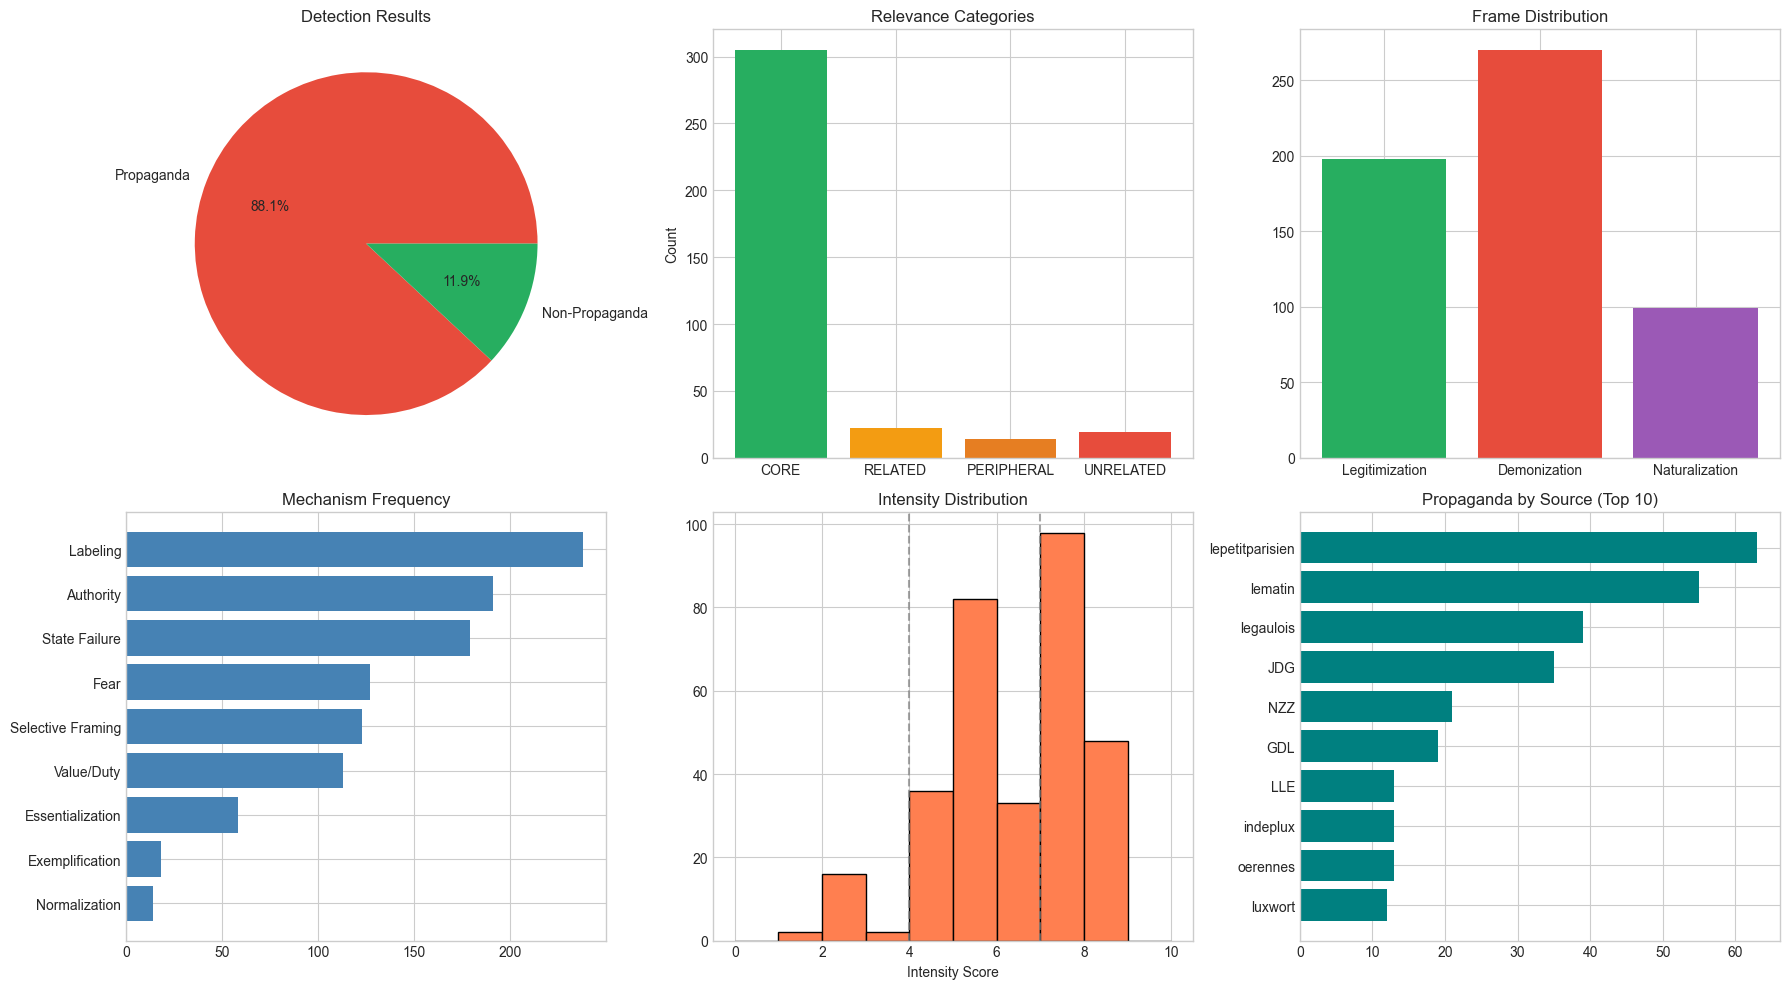

✓ Exported files:
  - json: perdicaris_20251214_153224.json
  - summary: perdicaris_summary_20251214_153224.csv
  - strategies: perdicaris_strategies_20251214_153224.csv
  - tropes: perdicaris_tropes_20251214_153224.csv


{'json': 'perdicaris_20251214_153224.json',
 'summary': 'perdicaris_summary_20251214_153224.csv',
 'strategies': 'perdicaris_strategies_20251214_153224.csv',
 'tropes': 'perdicaris_tropes_20251214_153224.csv'}

In [ ]:
results = analyze_batch_from_json(
    filepath="perdicaris_perdicaris.json",
    model="gpt-4o",
    delay=1.5,
    max_articles=None,   # Process ALL articles
    save_interval=25     # Save interim results every 25 articles
)

# Display first 5 as preview
for r in results[:5]:
    display_result_html(r)

# Charts for full corpus
display_batch_charts(results)

# Export everything
export_all_results(results, prefix="perdicaris")

In [ ]:
def load_results(json_filepath: str) -> List[Dict]:
    """Reload results from exported JSON file."""
    with open(json_filepath, 'r', encoding='utf-8') as f:
        results = json.load(f)
    print(f"✓ Loaded {len(results)} articles from {json_filepath}")

    # Quick summary
    prop_count = sum(1 for r in results if r.get('isPropaganda', False))
    print(f"  Propaganda: {prop_count}/{len(results)} ({100*prop_count/len(results):.1f}%)")

    return results

In [ ]:
# ═══════════════════════════════════════════════════════════════════
# LOAD DATA
# ═══════════════════════════════════════════════════════════════════

results = load_results("perdicaris_20251214_153224.json")

# Create all dataframes
df = results_to_dataframe(results)
df_strat = strategies_to_dataframe(results)
df_tropes = tropes_to_dataframe(results)

# Convert date to datetime
df['date'] = pd.to_datetime(df['date'], errors='coerce')
df_strat['date'] = pd.to_datetime(df_strat['date'], errors='coerce')

print(f"✓ DataFrames created:")
print(f"  - Articles: {len(df)} rows")
print(f"  - Mechanisms: {len(df_strat)} rows")
print(f"  - Tropes: {len(df_tropes)} rows")

✓ Loaded 360 articles from perdicaris_20251214_153224.json
  Propaganda: 317/360 (88.1%)
✓ DataFrames created:
  - Articles: 360 rows
  - Mechanisms: 1061 rows
  - Tropes: 797 rows


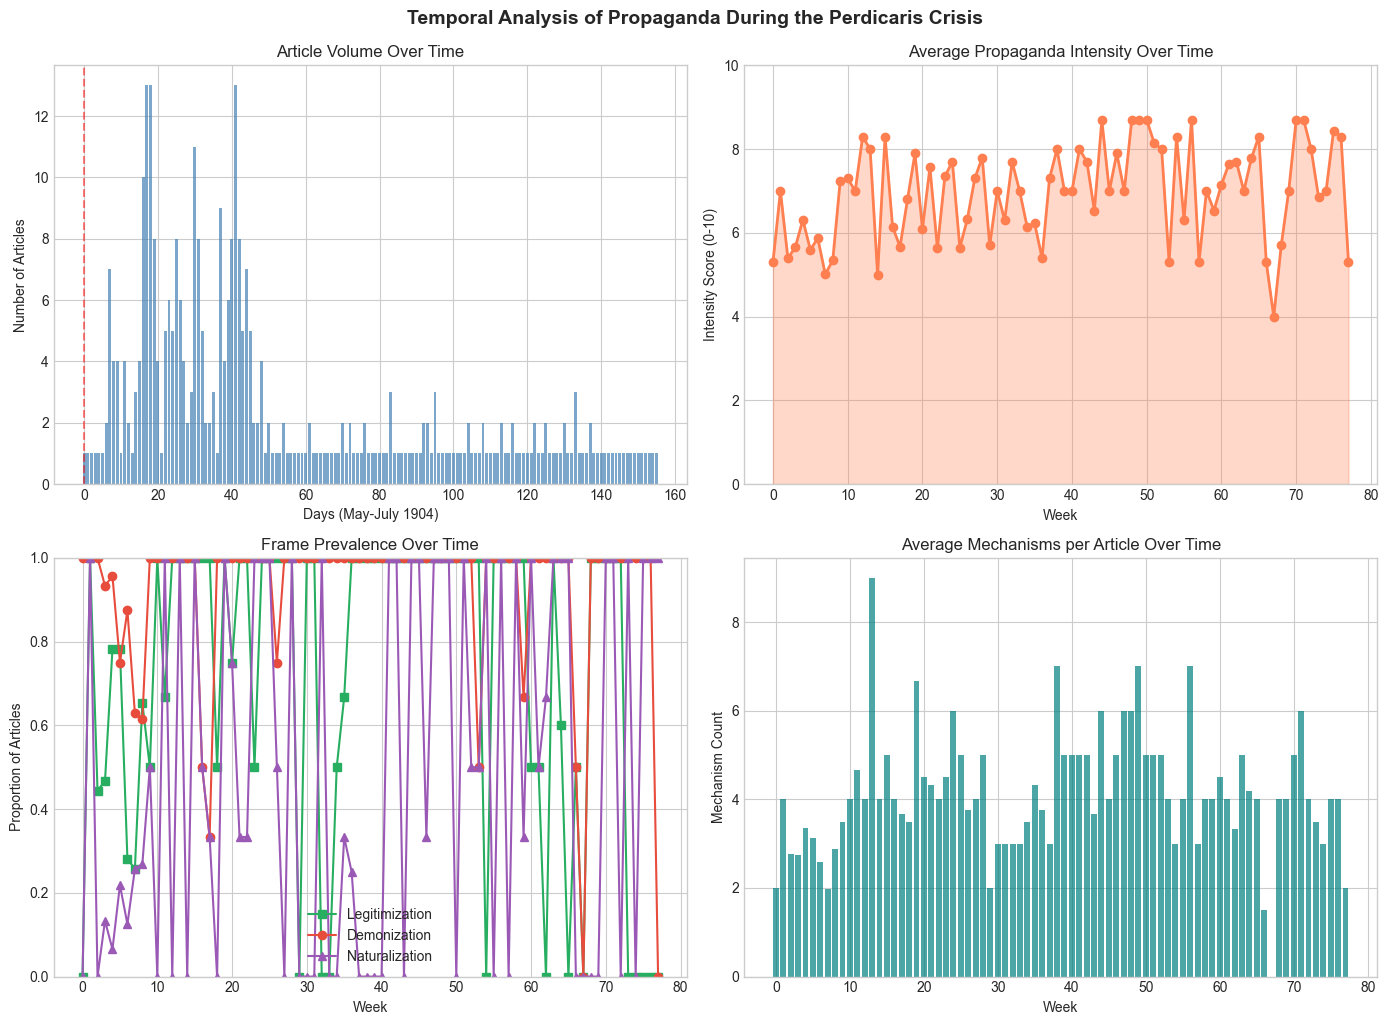

In [ ]:
# ═══════════════════════════════════════════════════════════════════
# 1. TEMPORAL ANALYSIS: Evolution over the crisis (May-July 1904)
# ═══════════════════════════════════════════════════════════════════

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Filter to propaganda articles with valid dates
df_prop = df[(df['isPropaganda'] == True) & (df['date'].notna())].copy()
df_prop['week'] = df_prop['date'].dt.strftime('%Y-W%U')

# 1a. Article volume over time
daily_counts = df.groupby(df['date'].dt.date).size()
axes[0, 0].bar(range(len(daily_counts)), daily_counts.values, color='steelblue', alpha=0.7)
axes[0, 0].set_title('Article Volume Over Time')
axes[0, 0].set_xlabel('Days (May-July 1904)')
axes[0, 0].set_ylabel('Number of Articles')
# Mark key dates
axes[0, 0].axvline(x=0, color='red', linestyle='--', alpha=0.5, label='May 18: Kidnapping')

# 1b. Intensity over time
weekly_intensity = df_prop.groupby('week')['intensity'].mean()
axes[0, 1].plot(range(len(weekly_intensity)), weekly_intensity.values, marker='o', linewidth=2, color='coral')
axes[0, 1].fill_between(range(len(weekly_intensity)), weekly_intensity.values, alpha=0.3, color='coral')
axes[0, 1].set_title('Average Propaganda Intensity Over Time')
axes[0, 1].set_xlabel('Week')
axes[0, 1].set_ylabel('Intensity Score (0-10)')
axes[0, 1].set_ylim(0, 10)

# 1c. Frame evolution over time
frame_weekly = df_prop.groupby('week')[['frame_legitimization', 'frame_demonization', 'frame_naturalization']].mean()
x = range(len(frame_weekly))
axes[1, 0].plot(x, frame_weekly['frame_legitimization'], marker='s', label='Legitimization', color='#27ae60')
axes[1, 0].plot(x, frame_weekly['frame_demonization'], marker='o', label='Demonization', color='#e74c3c')
axes[1, 0].plot(x, frame_weekly['frame_naturalization'], marker='^', label='Naturalization', color='#9b59b6')
axes[1, 0].set_title('Frame Prevalence Over Time')
axes[1, 0].set_xlabel('Week')
axes[1, 0].set_ylabel('Proportion of Articles')
axes[1, 0].legend()
axes[1, 0].set_ylim(0, 1)

# 1d. Mechanism count over time
weekly_mechs = df_prop.groupby('week')['strategiesCount'].mean()
axes[1, 1].bar(range(len(weekly_mechs)), weekly_mechs.values, color='teal', alpha=0.7)
axes[1, 1].set_title('Average Mechanisms per Article Over Time')
axes[1, 1].set_xlabel('Week')
axes[1, 1].set_ylabel('Mechanism Count')

plt.tight_layout()
plt.suptitle('Temporal Analysis of Propaganda During the Perdicaris Crisis', y=1.02, fontsize=14, fontweight='bold')
plt.show()

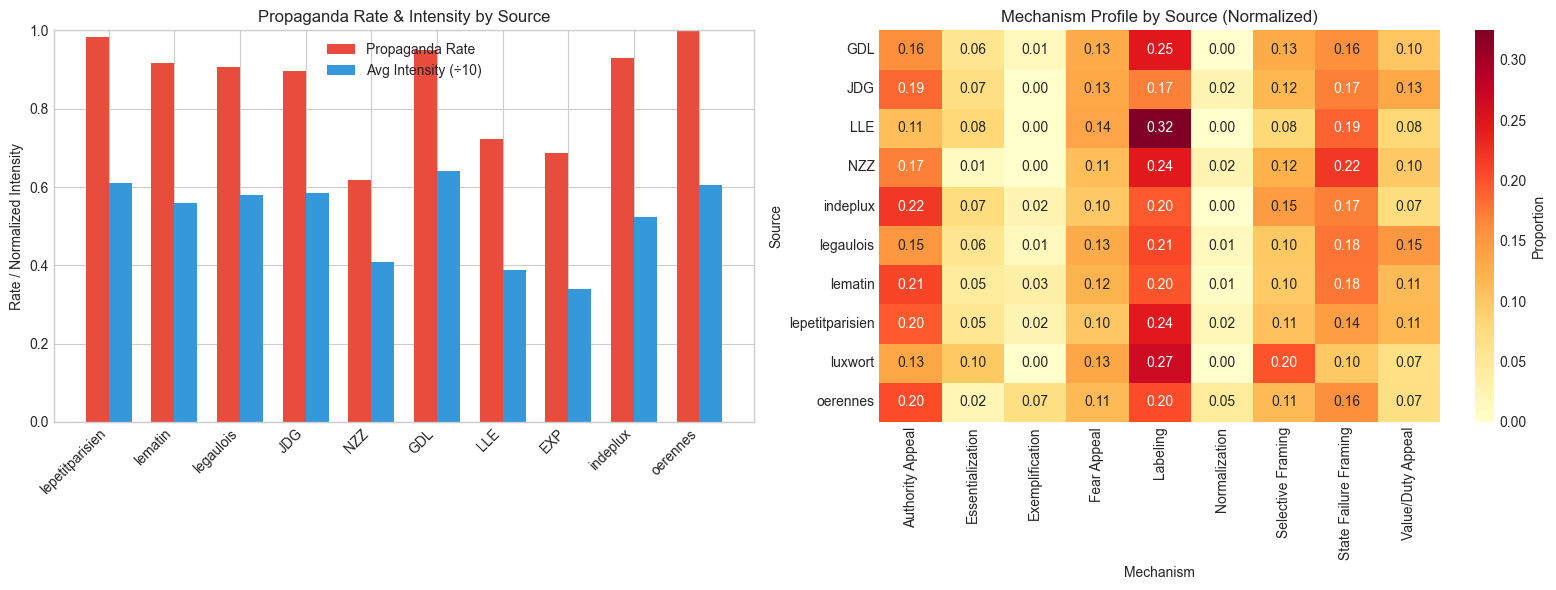


📊 Source Statistics:
                 prop_count  total  prop_rate  avg_intensity
source                                                      
lepetitparisien          63     64      0.984          6.114
lematin                  55     60      0.917          5.595
legaulois                39     43      0.907          5.798
JDG                      35     39      0.897          5.851
NZZ                      21     34      0.618          4.076
GDL                      19     20      0.950          6.415
LLE                      13     18      0.722          3.889
EXP                      11     16      0.688          3.400
indeplux                 13     14      0.929          5.243
oerennes                 13     13      1.000          6.062


In [ ]:
# ═══════════════════════════════════════════════════════════════════
# 2. SOURCE COMPARISON: Which newspapers use which mechanisms?
# ═══════════════════════════════════════════════════════════════════

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 2a. Propaganda rate by source (normalized)
source_stats = df.groupby('source').agg({
    'isPropaganda': ['sum', 'count', 'mean'],
    'intensity': 'mean'
}).round(3)
source_stats.columns = ['prop_count', 'total', 'prop_rate', 'avg_intensity']
source_stats = source_stats.sort_values('total', ascending=False).head(10)

x = range(len(source_stats))
width = 0.35
axes[0].bar([i - width/2 for i in x], source_stats['prop_rate'], width, label='Propaganda Rate', color='#e74c3c')
axes[0].bar([i + width/2 for i in x], source_stats['avg_intensity']/10, width, label='Avg Intensity (÷10)', color='#3498db')
axes[0].set_xticks(x)
axes[0].set_xticklabels(source_stats.index, rotation=45, ha='right')
axes[0].set_title('Propaganda Rate & Intensity by Source')
axes[0].set_ylabel('Rate / Normalized Intensity')
axes[0].legend()
axes[0].set_ylim(0, 1)

# 2b. Mechanism profile by source (heatmap)
source_mechs = df_strat.groupby(['source', 'mechanism_name']).size().unstack(fill_value=0)
# Normalize by source total
source_mechs_norm = source_mechs.div(source_mechs.sum(axis=1), axis=0)
# Top 10 sources
top_sources = df_strat['source'].value_counts().head(10).index
source_mechs_norm = source_mechs_norm.loc[source_mechs_norm.index.isin(top_sources)]

sns.heatmap(source_mechs_norm, cmap='YlOrRd', annot=True, fmt='.2f', ax=axes[1], cbar_kws={'label': 'Proportion'})
axes[1].set_title('Mechanism Profile by Source (Normalized)')
axes[1].set_xlabel('Mechanism')
axes[1].set_ylabel('Source')

plt.tight_layout()
plt.show()

# Print summary table
print("\n📊 Source Statistics:")
print(source_stats.to_string())

In [ ]:
import numpy as np

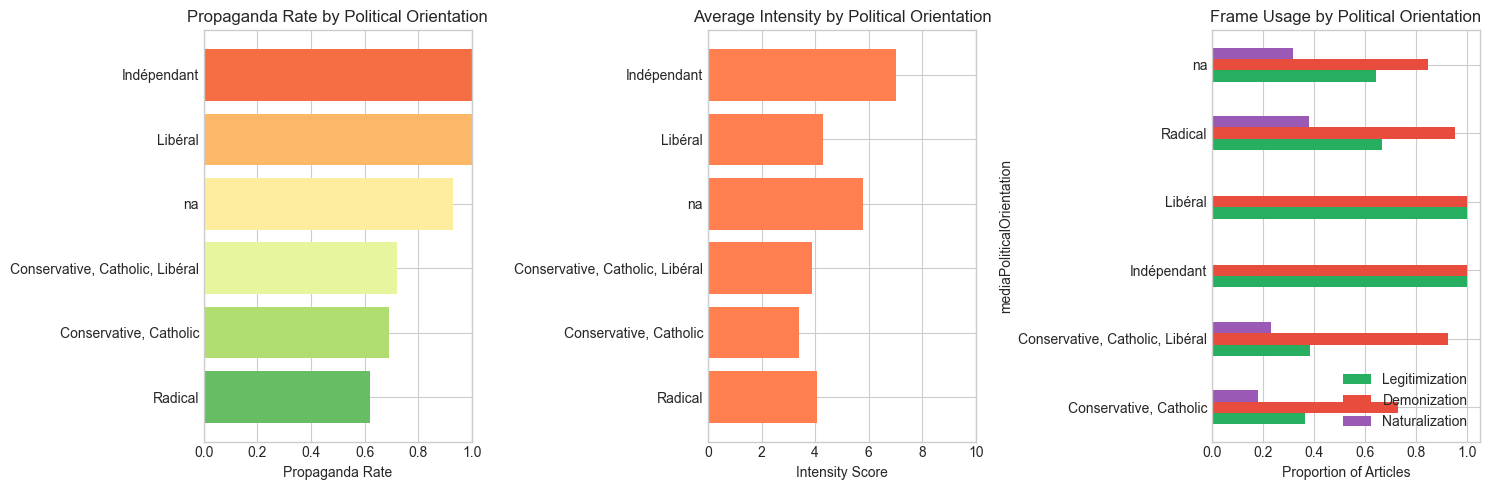

In [ ]:
# ═══════════════════════════════════════════════════════════════════
# 3. POLITICAL ORIENTATION ANALYSIS
# ═══════════════════════════════════════════════════════════════════

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Filter to articles with political orientation data
df_pol = df[df['mediaPoliticalOrientation'].notna() & (df['mediaPoliticalOrientation'] != '')]

if len(df_pol) > 0:
    # 3a. Propaganda rate by political orientation
    pol_stats = df_pol.groupby('mediaPoliticalOrientation').agg({
        'isPropaganda': 'mean',
        'intensity': 'mean',
        'id': 'count'
    }).round(2)
    pol_stats.columns = ['prop_rate', 'avg_intensity', 'count']
    pol_stats = pol_stats.sort_values('prop_rate', ascending=True)

    colors = plt.cm.RdYlGn(np.linspace(0.2, 0.8, len(pol_stats)))[::-1]
    axes[0].barh(pol_stats.index, pol_stats['prop_rate'], color=colors)
    axes[0].set_title('Propaganda Rate by Political Orientation')
    axes[0].set_xlabel('Propaganda Rate')
    axes[0].set_xlim(0, 1)

    # 3b. Intensity by political orientation
    axes[1].barh(pol_stats.index, pol_stats['avg_intensity'], color='coral')
    axes[1].set_title('Average Intensity by Political Orientation')
    axes[1].set_xlabel('Intensity Score')
    axes[1].set_xlim(0, 10)

    # 3c. Frame preference by political orientation
    frame_by_pol = df_pol[df_pol['isPropaganda']].groupby('mediaPoliticalOrientation')[
        ['frame_legitimization', 'frame_demonization', 'frame_naturalization']
    ].mean()

    frame_by_pol.plot(kind='barh', ax=axes[2], color=['#27ae60', '#e74c3c', '#9b59b6'])
    axes[2].set_title('Frame Usage by Political Orientation')
    axes[2].set_xlabel('Proportion of Articles')
    axes[2].legend(['Legitimization', 'Demonization', 'Naturalization'], loc='lower right')

    plt.tight_layout()
    plt.show()
else:
    print("⚠️ No political orientation data available")

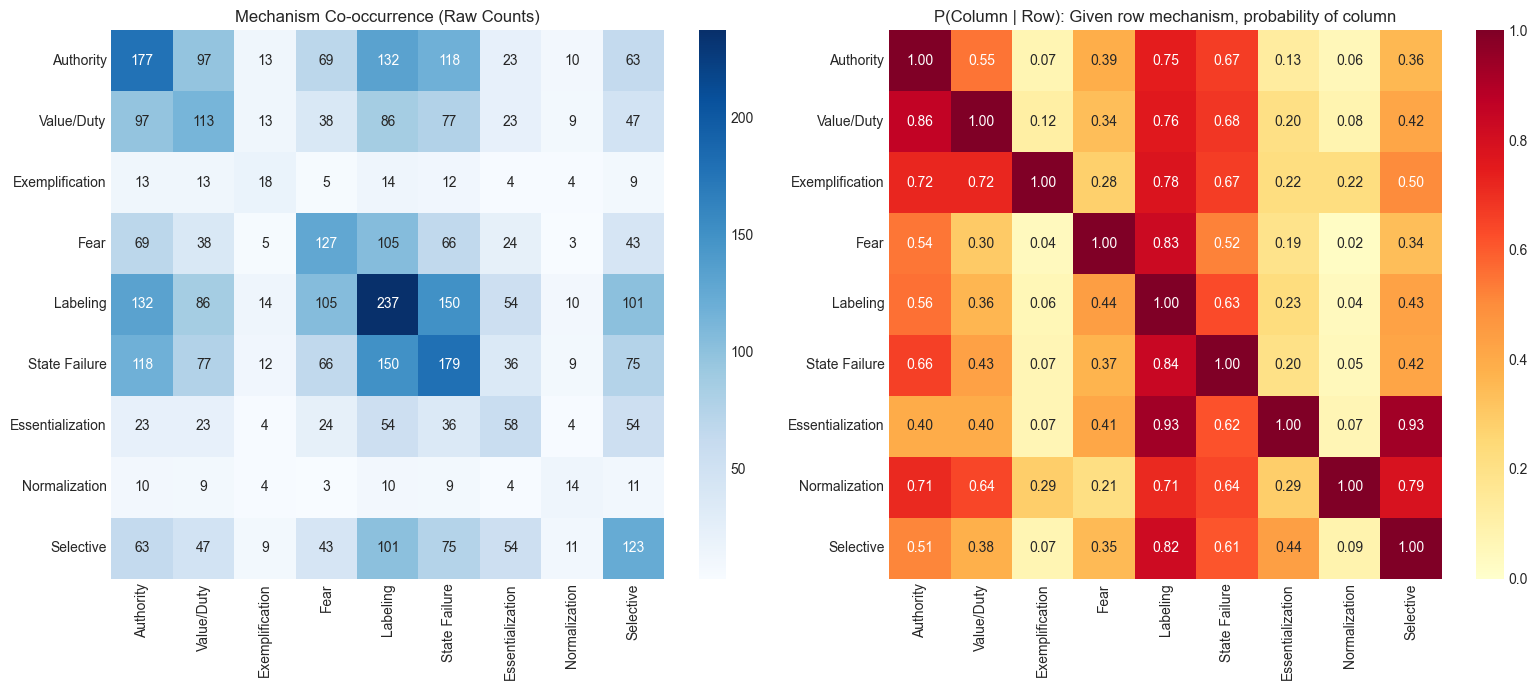


🔗 Strongest Mechanism Pairs:
  Labeling + State Failure: 150 articles
  Authority Appeal + Labeling: 132 articles
  Authority Appeal + State Failure: 118 articles
  Fear Appeal + Labeling: 105 articles
  Labeling + Selective Framing: 101 articles
  Authority Appeal + Value/Duty Appeal: 97 articles
  Value/Duty Appeal + Labeling: 86 articles
  Value/Duty Appeal + State Failure: 77 articles
  State Failure + Selective Framing: 75 articles
  Authority Appeal + Fear Appeal: 69 articles


In [ ]:
# ═══════════════════════════════════════════════════════════════════
# 4. MECHANISM CO-OCCURRENCE ANALYSIS
# ═══════════════════════════════════════════════════════════════════

mechanism_names = {
    1: 'Authority Appeal', 2: 'Value/Duty Appeal', 3: 'Exemplification',
    4: 'Fear Appeal', 5: 'Labeling', 6: 'State Failure',
    7: 'Essentialization', 8: 'Normalization', 9: 'Selective Framing'
}

# Build co-occurrence matrix
cooccur = np.zeros((9, 9))
for r in results:
    if not r.get('isPropaganda'):
        continue
    mechs = [s.get('mechanism_id', 0) for s in r.get('strategies', []) if s.get('mechanism_id')]
    mechs = list(set(mechs))  # Unique mechanisms per article
    for i in mechs:
        for j in mechs:
            if 1 <= i <= 9 and 1 <= j <= 9:
                cooccur[i-1][j-1] += 1

# Normalize to proportions (excluding diagonal)
cooccur_norm = cooccur.copy()
for i in range(9):
    row_sum = cooccur[i].sum() - cooccur[i][i]  # Exclude self
    if row_sum > 0:
        cooccur_norm[i] = cooccur[i] / cooccur[i][i]  # Proportion relative to mechanism's own occurrence
    cooccur_norm[i][i] = 1  # Self = 1

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# 4a. Raw co-occurrence counts
labels = [mechanism_names[i+1].replace(' Appeal', '').replace(' Framing', '') for i in range(9)]
sns.heatmap(cooccur, xticklabels=labels, yticklabels=labels,
            annot=True, fmt='.0f', cmap='Blues', ax=axes[0])
axes[0].set_title('Mechanism Co-occurrence (Raw Counts)')

# 4b. Which mechanisms predict which others?
# P(col | row) = how often does column appear when row appears?
cooccur_conditional = cooccur.copy()
for i in range(9):
    if cooccur[i][i] > 0:
        cooccur_conditional[i] = cooccur[i] / cooccur[i][i]

sns.heatmap(cooccur_conditional, xticklabels=labels, yticklabels=labels,
            annot=True, fmt='.2f', cmap='YlOrRd', ax=axes[1], vmin=0, vmax=1)
axes[1].set_title('P(Column | Row): Given row mechanism, probability of column')

plt.tight_layout()
plt.show()

# Find strongest co-occurrences (excluding self)
print("\n🔗 Strongest Mechanism Pairs:")
pairs = []
for i in range(9):
    for j in range(i+1, 9):
        pairs.append((mechanism_names[i+1], mechanism_names[j+1], cooccur[i][j]))
pairs.sort(key=lambda x: x[2], reverse=True)
for m1, m2, count in pairs[:10]:
    print(f"  {m1} + {m2}: {int(count)} articles")

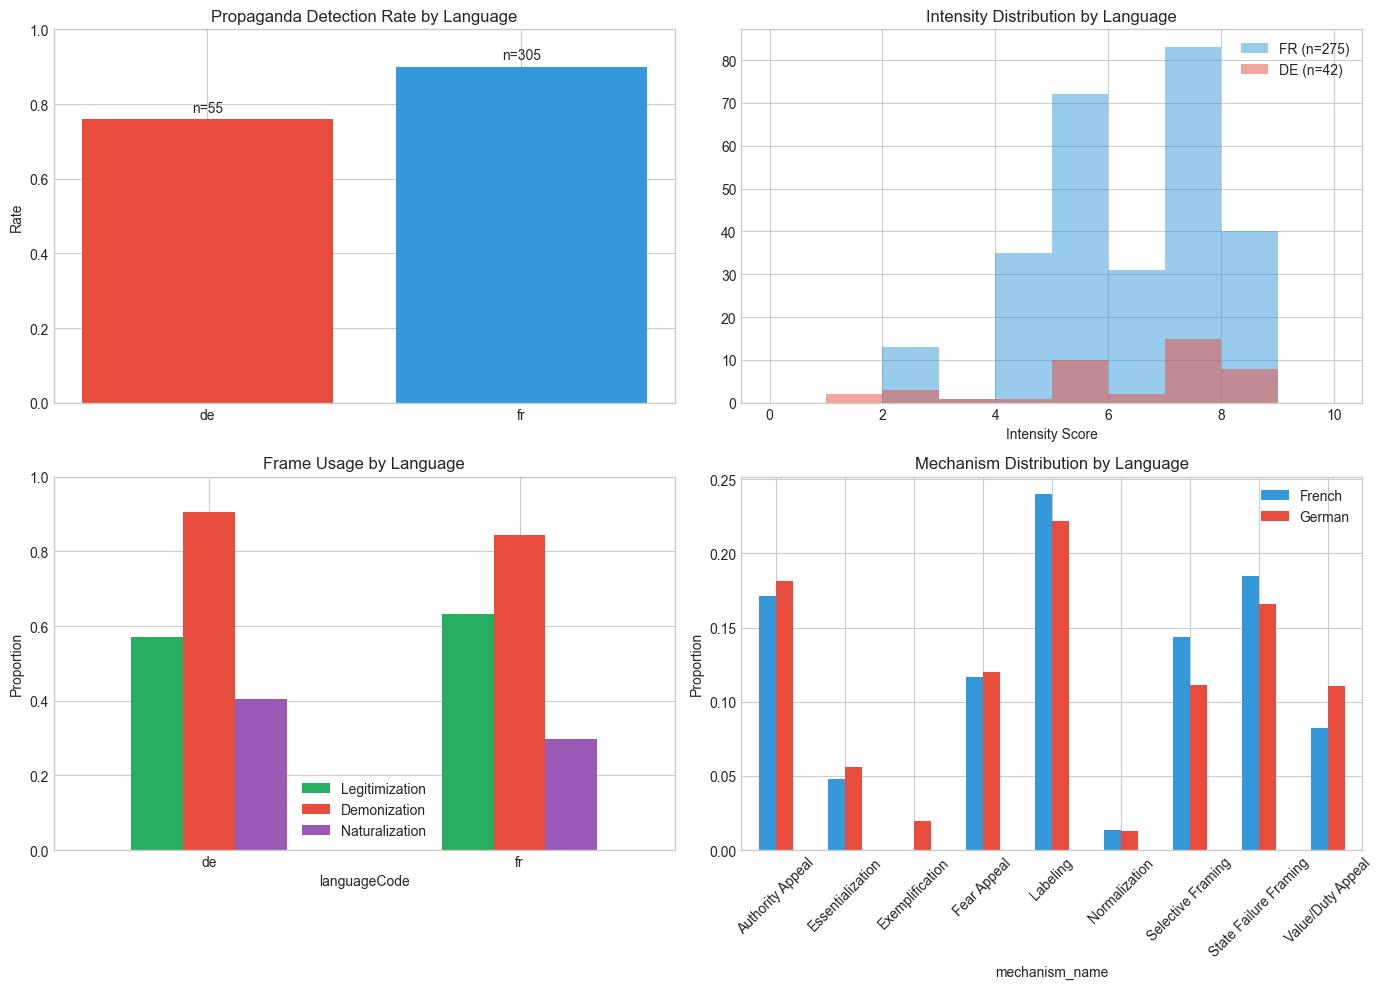


📊 Language Statistics:
              prop_count  total  prop_rate  avg_intensity
languageCode                                             
de                    42     55       0.76           4.71
fr                   275    305       0.90           5.57


In [ ]:
# ═══════════════════════════════════════════════════════════════════
# 5. LANGUAGE COMPARISON (French vs German)
# ═══════════════════════════════════════════════════════════════════

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

df_lang = df[df['languageCode'].isin(['fr', 'de'])]

# 5a. Propaganda rate by language
lang_stats = df_lang.groupby('languageCode').agg({
    'isPropaganda': ['sum', 'count', 'mean'],
    'intensity': 'mean'
}).round(2)
lang_stats.columns = ['prop_count', 'total', 'prop_rate', 'avg_intensity']

colors = {'fr': '#3498db', 'de': '#e74c3c'}
axes[0, 0].bar(lang_stats.index, lang_stats['prop_rate'], color=[colors.get(x, 'gray') for x in lang_stats.index])
axes[0, 0].set_title('Propaganda Detection Rate by Language')
axes[0, 0].set_ylabel('Rate')
axes[0, 0].set_ylim(0, 1)
for i, (idx, row) in enumerate(lang_stats.iterrows()):
    axes[0, 0].annotate(f"n={int(row['total'])}", (i, row['prop_rate'] + 0.02), ha='center')

# 5b. Intensity distribution by language
df_lang_prop = df_lang[df_lang['isPropaganda'] == True]
for lang, color in colors.items():
    data = df_lang_prop[df_lang_prop['languageCode'] == lang]['intensity']
    if len(data) > 0:
        axes[0, 1].hist(data, bins=10, range=(0, 10), alpha=0.5, label=f'{lang.upper()} (n={len(data)})', color=color)
axes[0, 1].set_title('Intensity Distribution by Language')
axes[0, 1].set_xlabel('Intensity Score')
axes[0, 1].legend()

# 5c. Frame usage by language
frame_by_lang = df_lang_prop.groupby('languageCode')[
    ['frame_legitimization', 'frame_demonization', 'frame_naturalization']
].mean()
frame_by_lang.plot(kind='bar', ax=axes[1, 0], color=['#27ae60', '#e74c3c', '#9b59b6'], rot=0)
axes[1, 0].set_title('Frame Usage by Language')
axes[1, 0].set_ylabel('Proportion')
axes[1, 0].legend(['Legitimization', 'Demonization', 'Naturalization'])
axes[1, 0].set_ylim(0, 1)

# 5d. Mechanism usage by language
mech_by_lang = df_strat[df_strat['languageCode'].isin(['fr', 'de'])].groupby(
    ['languageCode', 'mechanism_name']
).size().unstack(fill_value=0)
# Normalize
mech_by_lang_norm = mech_by_lang.div(mech_by_lang.sum(axis=1), axis=0)
mech_by_lang_norm.T.plot(kind='bar', ax=axes[1, 1], rot=45, color=[colors['fr'], colors['de']])
axes[1, 1].set_title('Mechanism Distribution by Language')
axes[1, 1].set_ylabel('Proportion')
axes[1, 1].legend(['French', 'German'])

plt.tight_layout()
plt.show()

print("\n📊 Language Statistics:")
print(lang_stats.to_string())

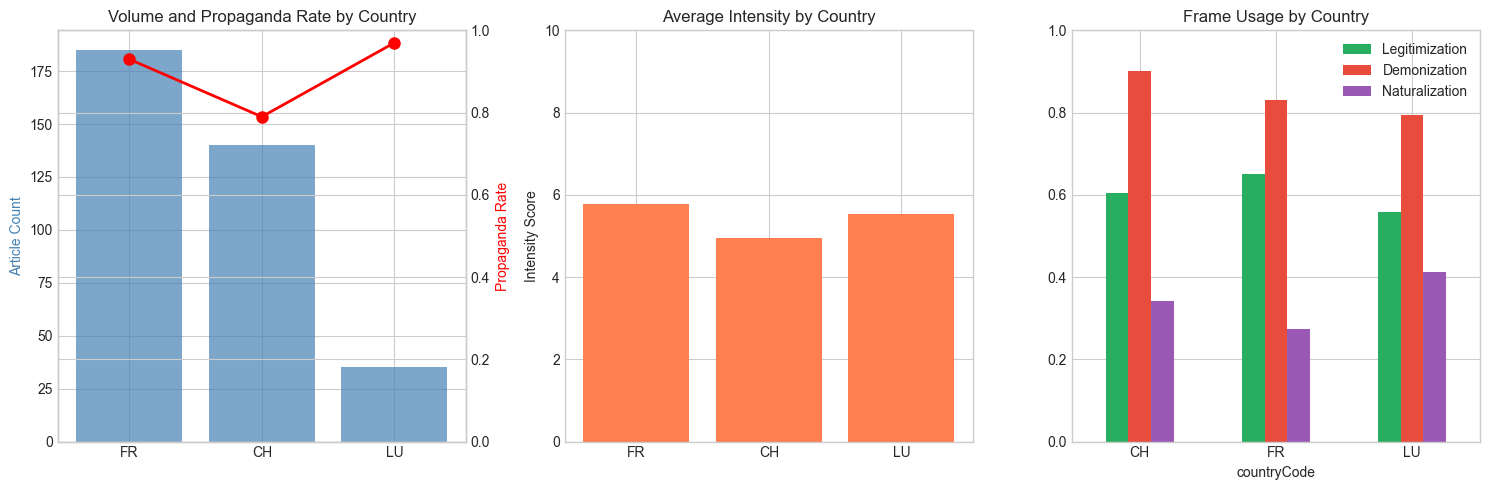

In [ ]:
# ═══════════════════════════════════════════════════════════════════
# 6. COUNTRY COMPARISON
# ═══════════════════════════════════════════════════════════════════

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

country_stats = df.groupby('countryCode').agg({
    'isPropaganda': ['sum', 'count', 'mean'],
    'intensity': 'mean',
    'strategiesCount': 'mean'
}).round(2)
country_stats.columns = ['prop_count', 'total', 'prop_rate', 'avg_intensity', 'avg_mechanisms']
country_stats = country_stats.sort_values('total', ascending=False)

# 6a. Volume and propaganda rate
x = range(len(country_stats))
ax1 = axes[0]
ax2 = ax1.twinx()
ax1.bar(x, country_stats['total'], alpha=0.7, color='steelblue', label='Total Articles')
ax2.plot(x, country_stats['prop_rate'], 'ro-', linewidth=2, markersize=8, label='Propaganda Rate')
ax1.set_xticks(x)
ax1.set_xticklabels(country_stats.index)
ax1.set_ylabel('Article Count', color='steelblue')
ax2.set_ylabel('Propaganda Rate', color='red')
ax2.set_ylim(0, 1)
ax1.set_title('Volume and Propaganda Rate by Country')

# 6b. Intensity by country
axes[1].bar(country_stats.index, country_stats['avg_intensity'], color='coral')
axes[1].set_title('Average Intensity by Country')
axes[1].set_ylabel('Intensity Score')
axes[1].set_ylim(0, 10)

# 6c. Frame usage by country
frame_by_country = df[df['isPropaganda']].groupby('countryCode')[
    ['frame_legitimization', 'frame_demonization', 'frame_naturalization']
].mean()
frame_by_country.plot(kind='bar', ax=axes[2], color=['#27ae60', '#e74c3c', '#9b59b6'], rot=0)
axes[2].set_title('Frame Usage by Country')
axes[2].legend(['Legitimization', 'Demonization', 'Naturalization'])
axes[2].set_ylim(0, 1)

plt.tight_layout()
plt.show()

C:\Users\ferdaous.affan\AppData\Local\Temp\ipykernel_62044\163885587.py:25: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  top_per_frame = frame_tropes.groupby('frame').apply(


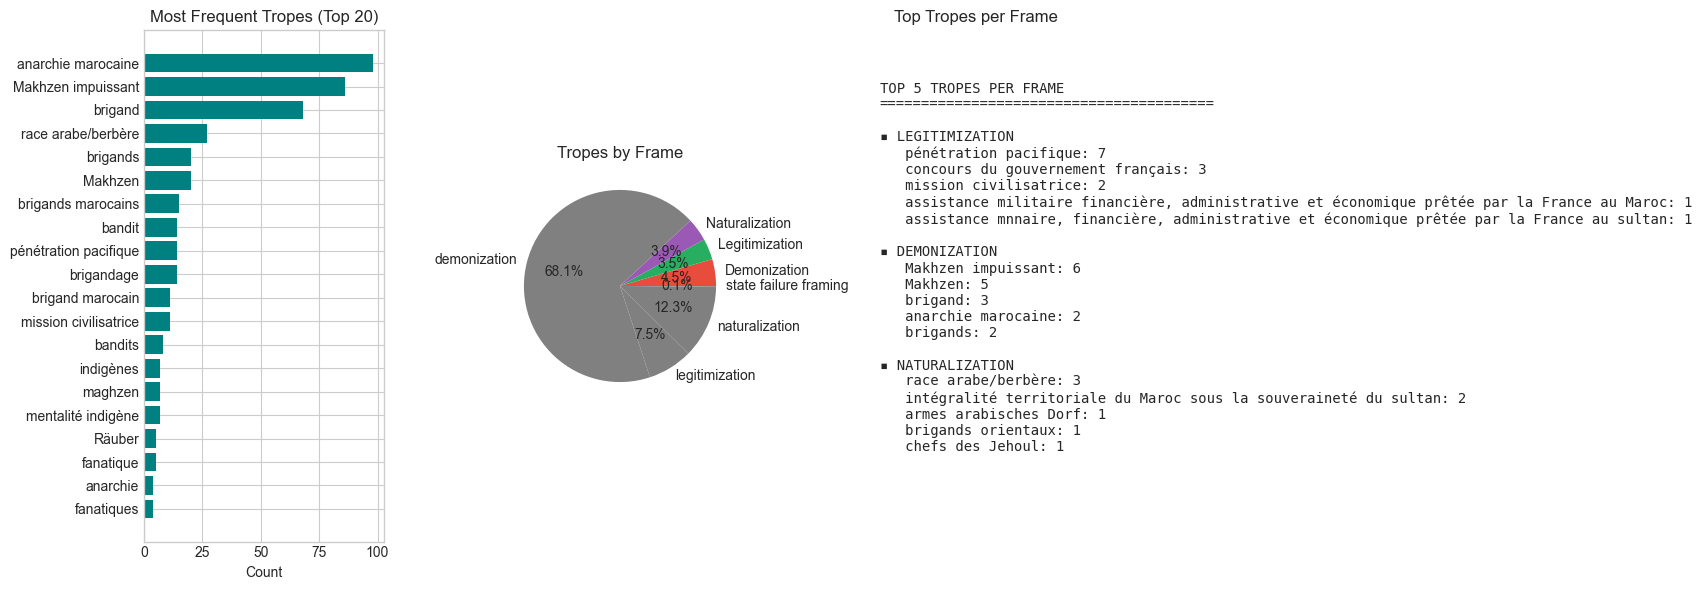

In [ ]:
# ═══════════════════════════════════════════════════════════════════
# 7. TROPE ANALYSIS
# ═══════════════════════════════════════════════════════════════════

fig, axes = plt.subplots(1, 3, figsize=(16, 6))

# 7a. Most common tropes (top 20)
trope_freq = df_tropes['trope_term'].value_counts().head(20)
axes[0].barh(range(len(trope_freq)), trope_freq.values, color='teal')
axes[0].set_yticks(range(len(trope_freq)))
axes[0].set_yticklabels(trope_freq.index)
axes[0].invert_yaxis()
axes[0].set_title('Most Frequent Tropes (Top 20)')
axes[0].set_xlabel('Count')

# 7b. Tropes by frame
trope_by_frame = df_tropes.groupby('frame')['trope_term'].count()
colors = {'Legitimization': '#27ae60', 'Demonization': '#e74c3c', 'Naturalization': '#9b59b6'}
axes[1].pie(trope_by_frame.values, labels=trope_by_frame.index, autopct='%1.1f%%',
            colors=[colors.get(x, 'gray') for x in trope_by_frame.index])
axes[1].set_title('Tropes by Frame')

# 7c. Top tropes per frame
frame_tropes = df_tropes.groupby(['frame', 'trope_term']).size().reset_index(name='count')
top_per_frame = frame_tropes.groupby('frame').apply(
    lambda x: x.nlargest(5, 'count')
).reset_index(drop=True)

# Display as text
axes[2].axis('off')
text = "TOP 5 TROPES PER FRAME\n" + "="*40 + "\n\n"
for frame in ['Legitimization', 'Demonization', 'Naturalization']:
    text += f"▪ {frame.upper()}\n"
    frame_data = top_per_frame[top_per_frame['frame'] == frame]
    for _, row in frame_data.iterrows():
        text += f"   {row['trope_term']}: {row['count']}\n"
    text += "\n"
axes[2].text(0.1, 0.9, text, transform=axes[2].transAxes, fontsize=10,
             verticalalignment='top', fontfamily='monospace')
axes[2].set_title('Top Tropes per Frame')

plt.tight_layout()
plt.show()

C:\Users\ferdaous.affan\AppData\Local\Temp\ipykernel_62044\2684574622.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=subscores, x='variable', y='value', ax=axes[0, 0], palette='Set2')
C:\Users\ferdaous.affan\AppData\Local\Temp\ipykernel_62044\2684574622.py:13: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0, 0].set_xticklabels(['Density', 'Explicitness', 'Emotional Impact'])
C:\Users\ferdaous.affan\AppData\Local\Temp\ipykernel_62044\2684574622.py:25: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_p

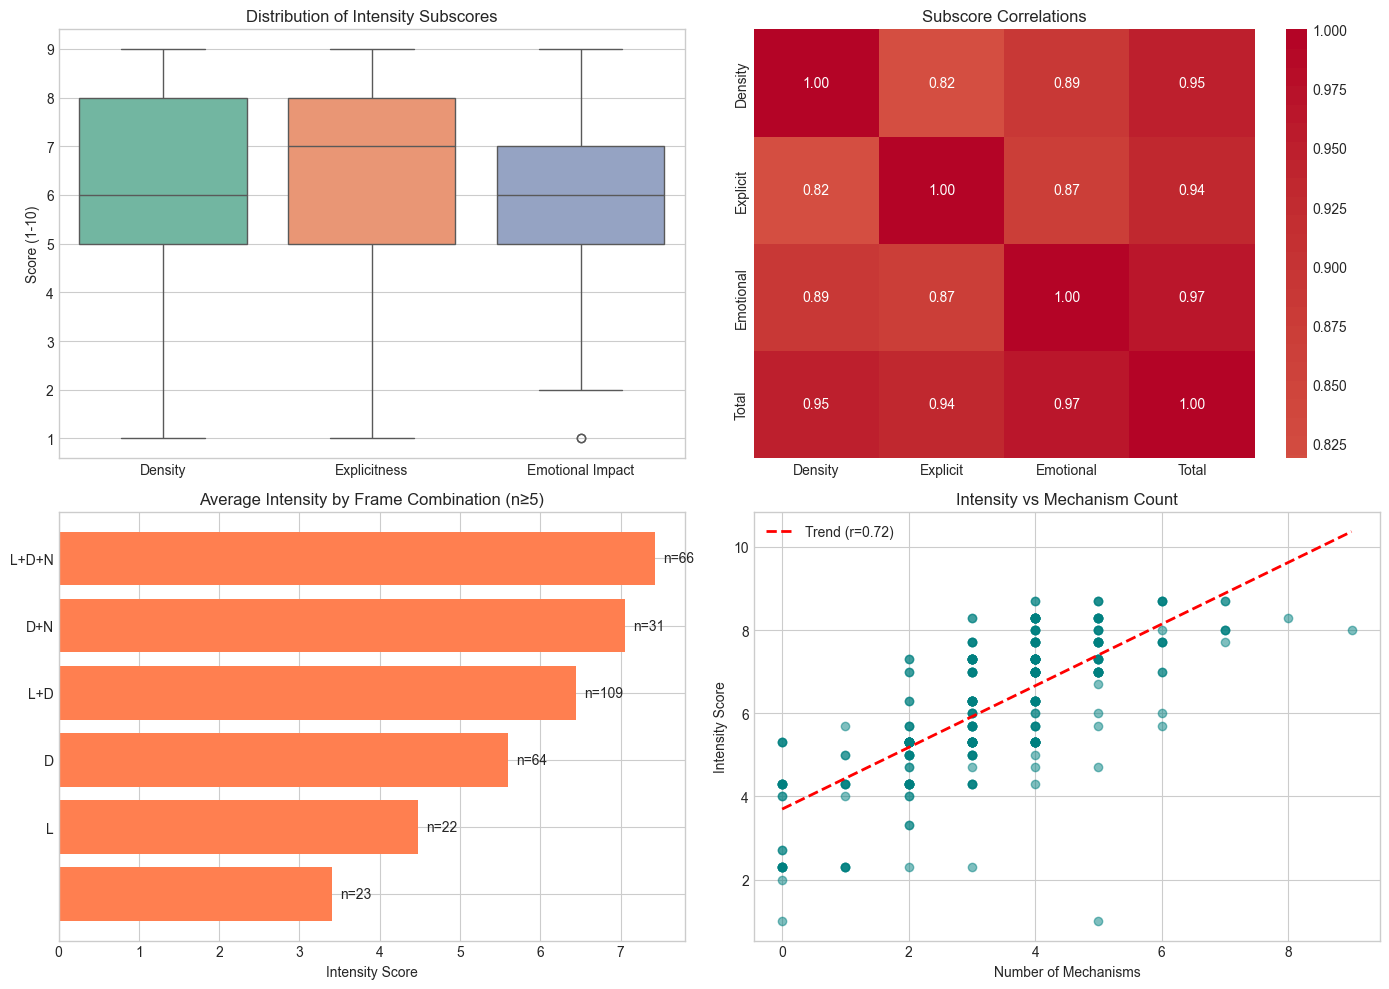

In [ ]:
# ═══════════════════════════════════════════════════════════════════
# 8. INTENSITY DEEP DIVE
# ═══════════════════════════════════════════════════════════════════

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

df_prop = df[df['isPropaganda'] == True]

# 8a. Subscores distribution
subscores = df_prop[['densityScore', 'explicitnessScore', 'emotionalImpactScore']].melt()
sns.boxplot(data=subscores, x='variable', y='value', ax=axes[0, 0], palette='Set2')
axes[0, 0].set_title('Distribution of Intensity Subscores')
axes[0, 0].set_xticklabels(['Density', 'Explicitness', 'Emotional Impact'])
axes[0, 0].set_ylabel('Score (1-10)')
axes[0, 0].set_xlabel('')

# 8b. Subscore correlations
subscore_corr = df_prop[['densityScore', 'explicitnessScore', 'emotionalImpactScore', 'intensity']].corr()
sns.heatmap(subscore_corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=axes[0, 1],
            xticklabels=['Density', 'Explicit', 'Emotional', 'Total'],
            yticklabels=['Density', 'Explicit', 'Emotional', 'Total'])
axes[0, 1].set_title('Subscore Correlations')

# 8c. Intensity by frame combination
df_prop['frame_combo'] = df_prop.apply(
    lambda r: '+'.join([f for f, present in [
        ('L', r['frame_legitimization']),
        ('D', r['frame_demonization']),
        ('N', r['frame_naturalization'])
    ] if present]), axis=1
)
combo_intensity = df_prop.groupby('frame_combo')['intensity'].agg(['mean', 'count']).round(2)
combo_intensity = combo_intensity[combo_intensity['count'] >= 5].sort_values('mean', ascending=True)

axes[1, 0].barh(combo_intensity.index, combo_intensity['mean'], color='coral')
axes[1, 0].set_title('Average Intensity by Frame Combination (n≥5)')
axes[1, 0].set_xlabel('Intensity Score')
for i, (idx, row) in enumerate(combo_intensity.iterrows()):
    axes[1, 0].annotate(f"n={int(row['count'])}", (row['mean'] + 0.1, i), va='center')

# 8d. Intensity vs mechanism count
axes[1, 1].scatter(df_prop['strategiesCount'], df_prop['intensity'], alpha=0.5, color='teal')
# Add trend line
z = np.polyfit(df_prop['strategiesCount'], df_prop['intensity'], 1)
p = np.poly1d(z)
x_line = np.linspace(df_prop['strategiesCount'].min(), df_prop['strategiesCount'].max(), 100)
axes[1, 1].plot(x_line, p(x_line), 'r--', linewidth=2, label=f'Trend (r={df_prop["strategiesCount"].corr(df_prop["intensity"]):.2f})')
axes[1, 1].set_title('Intensity vs Mechanism Count')
axes[1, 1].set_xlabel('Number of Mechanisms')
axes[1, 1].set_ylabel('Intensity Score')
axes[1, 1].legend()

plt.tight_layout()
plt.show()

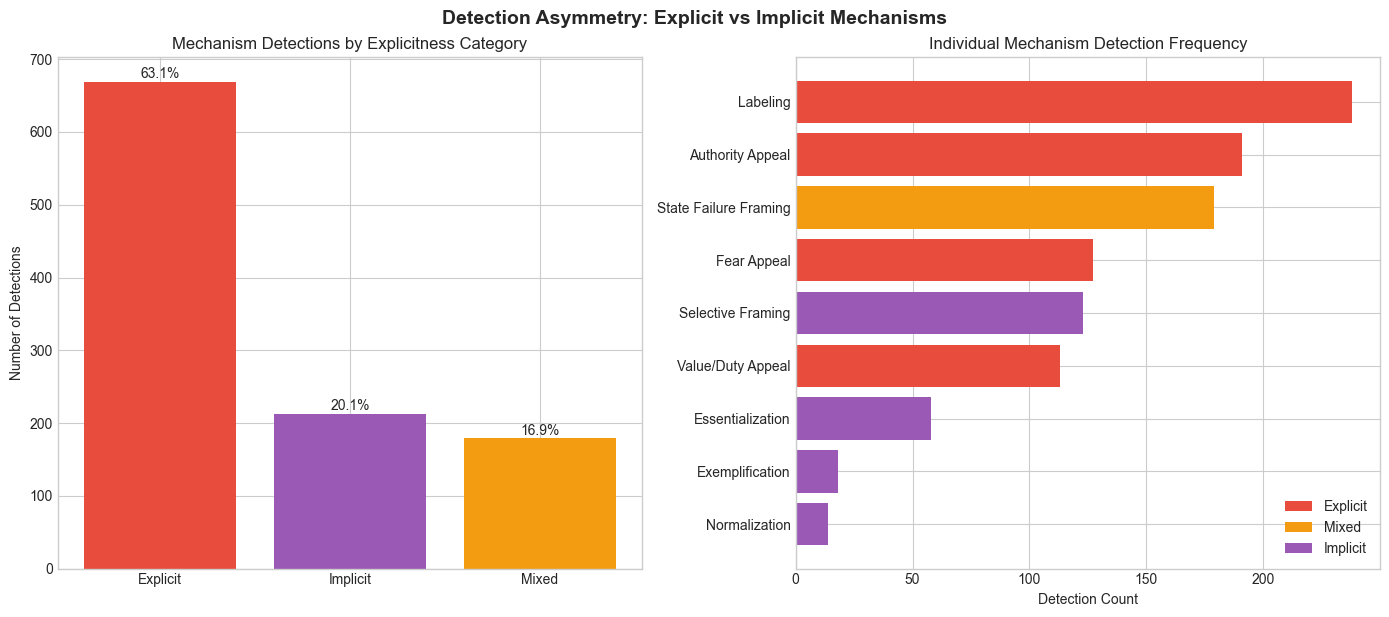


📊 Detection Asymmetry Summary:
Explicit: 669 detections (63.1%)
Mixed: 179 detections (16.9%)
Implicit: 213 detections (20.1%)

This supports the hypothesis that LLMs detect explicit
propaganda mechanisms more readily than implicit ones.


In [ ]:
# ═══════════════════════════════════════════════════════════════════
# 9. DETECTION ASYMMETRY ANALYSIS (Key finding!)
# ═══════════════════════════════════════════════════════════════════

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Categorize mechanisms by explicitness
explicit_mechanisms = ['Labeling', 'Fear Appeal', 'Authority Appeal', 'Value/Duty Appeal']
implicit_mechanisms = ['Normalization', 'Selective Framing', 'Essentialization', 'Exemplification']
mixed_mechanisms = ['State Failure Framing']  # Has both explicit vocabulary and implicit assumptions

df_strat['explicitness_category'] = df_strat['mechanism_name'].apply(
    lambda x: 'Explicit' if x in explicit_mechanisms else ('Implicit' if x in implicit_mechanisms else 'Mixed')
)

# 9a. Detection counts by explicitness category
cat_counts = df_strat['explicitness_category'].value_counts()
colors = {'Explicit': '#e74c3c', 'Implicit': '#9b59b6', 'Mixed': '#f39c12'}
axes[0].bar(cat_counts.index, cat_counts.values, color=[colors[x] for x in cat_counts.index])
axes[0].set_title('Mechanism Detections by Explicitness Category')
axes[0].set_ylabel('Number of Detections')

# Add annotation
total = cat_counts.sum()
for i, (cat, count) in enumerate(cat_counts.items()):
    axes[0].annotate(f'{count/total*100:.1f}%', (i, count + 5), ha='center')

# 9b. Individual mechanism comparison
mech_counts = df_strat['mechanism_name'].value_counts()
mech_colors = [colors.get(df_strat[df_strat['mechanism_name'] == m]['explicitness_category'].iloc[0], 'gray')
               for m in mech_counts.index]
axes[1].barh(range(len(mech_counts)), mech_counts.values, color=mech_colors)
axes[1].set_yticks(range(len(mech_counts)))
axes[1].set_yticklabels(mech_counts.index)
axes[1].invert_yaxis()
axes[1].set_title('Individual Mechanism Detection Frequency')
axes[1].set_xlabel('Detection Count')

# Add legend
from matplotlib.patches import Patch
legend_elements = [Patch(facecolor=colors['Explicit'], label='Explicit'),
                   Patch(facecolor=colors['Mixed'], label='Mixed'),
                   Patch(facecolor=colors['Implicit'], label='Implicit')]
axes[1].legend(handles=legend_elements, loc='lower right')

plt.tight_layout()
plt.suptitle('Detection Asymmetry: Explicit vs Implicit Mechanisms', y=1.02, fontsize=14, fontweight='bold')
plt.show()

# Statistical summary
print("\n📊 Detection Asymmetry Summary:")
print("="*50)
for cat in ['Explicit', 'Mixed', 'Implicit']:
    count = cat_counts.get(cat, 0)
    print(f"{cat}: {count} detections ({count/total*100:.1f}%)")
print("\nThis supports the hypothesis that LLMs detect explicit")
print("propaganda mechanisms more readily than implicit ones.")

In [ ]:
# ═══════════════════════════════════════════════════════════════════
# 10. SUMMARY STATISTICS TABLE
# ═══════════════════════════════════════════════════════════════════

print("="*70)
print("CORPUS SUMMARY STATISTICS")
print("="*70)

print(f"\n📰 CORPUS OVERVIEW")
print(f"   Total articles: {len(df)}")
print(f"   Date range: {df['date'].min().strftime('%Y-%m-%d')} to {df['date'].max().strftime('%Y-%m-%d')}")
print(f"   Languages: {df['languageCode'].value_counts().to_dict()}")
print(f"   Countries: {df['countryCode'].value_counts().to_dict()}")
print(f"   Sources: {df['source'].nunique()} unique newspapers")

print(f"\n🎯 RELEVANCE")
print(f"   {df['relevance_category'].value_counts().to_dict()}")

print(f"\n📊 PROPAGANDA DETECTION")
prop_count = df['isPropaganda'].sum()
print(f"   Propaganda detected: {prop_count}/{len(df)} ({100*prop_count/len(df):.1f}%)")
print(f"   Average confidence: {df[df['isPropaganda']]['confidence'].mean():.1f}%")

print(f"\n🔥 INTENSITY (propaganda articles only)")
df_prop = df[df['isPropaganda']]
print(f"   Average intensity: {df_prop['intensity'].mean():.2f}/10")
print(f"   Intensity levels: {df_prop['intensityLevel'].value_counts().to_dict()}")
print(f"   Subscores (mean): D={df_prop['densityScore'].mean():.1f}, E={df_prop['explicitnessScore'].mean():.1f}, Em={df_prop['emotionalImpactScore'].mean():.1f}")

print(f"\n🖼️ FRAMES")
print(f"   Legitimization: {df_prop['frame_legitimization'].sum()} articles ({100*df_prop['frame_legitimization'].mean():.1f}%)")
print(f"   Demonization: {df_prop['frame_demonization'].sum()} articles ({100*df_prop['frame_demonization'].mean():.1f}%)")
print(f"   Naturalization: {df_prop['frame_naturalization'].sum()} articles ({100*df_prop['frame_naturalization'].mean():.1f}%)")

print(f"\n⚙️ MECHANISMS")
print(f"   Total detections: {len(df_strat)}")
print(f"   Average per article: {df_prop['strategiesCount'].mean():.1f}")
print(f"   Top 3: {df_strat['mechanism_name'].value_counts().head(3).to_dict()}")

print(f"\n📝 TROPES")
print(f"   Total detections: {len(df_tropes)}")
print(f"   Unique terms: {df_tropes['trope_term'].nunique()}")
print(f"   Top 3: {df_tropes['trope_term'].value_counts().head(3).to_dict()}")

print("\n" + "="*70)

CORPUS SUMMARY STATISTICS

📰 CORPUS OVERVIEW
   Total articles: 360
   Date range: 1859-10-06 to 1938-08-13
   Languages: {'fr': 305, 'de': 55}
   Countries: {'FR': 185, 'CH': 140, 'LU': 35}
   Sources: 18 unique newspapers

🎯 RELEVANCE
   {'CORE': 305, 'RELATED': 22, 'UNRELATED': 19, 'PERIPHERAL': 14}

📊 PROPAGANDA DETECTION
   Propaganda detected: 317/360 (88.1%)
   Average confidence: 88.4%

🔥 INTENSITY (propaganda articles only)
   Average intensity: 6.18/10
   Intensity levels: {'Moderate': 151, 'Strong': 146, 'Weak': 20}
   Subscores (mean): D=6.1, E=6.5, Em=5.9

🖼️ FRAMES
   Legitimization: 198 articles (62.5%)
   Demonization: 270 articles (85.2%)
   Naturalization: 99 articles (31.2%)

⚙️ MECHANISMS
   Total detections: 1061
   Average per article: 3.3
   Top 3: {'Labeling': 238, 'Authority Appeal': 191, 'State Failure Framing': 179}

📝 TROPES
   Total detections: 797
   Unique terms: 331
   Top 3: {'anarchie marocaine': 98, 'Makhzen impuissant': 86, 'brigand': 68}



Date dtype: datetime64[ns, UTC]
Raw date range: 1859-10-06 00:00:00+00:00 to 1938-08-13 00:00:00+00:00

✓ Filtered to 1904: 251 articles (221 with propaganda)
Date range: 1904-05-20 00:00:00+00:00 to 1904-12-31 00:00:00+00:00


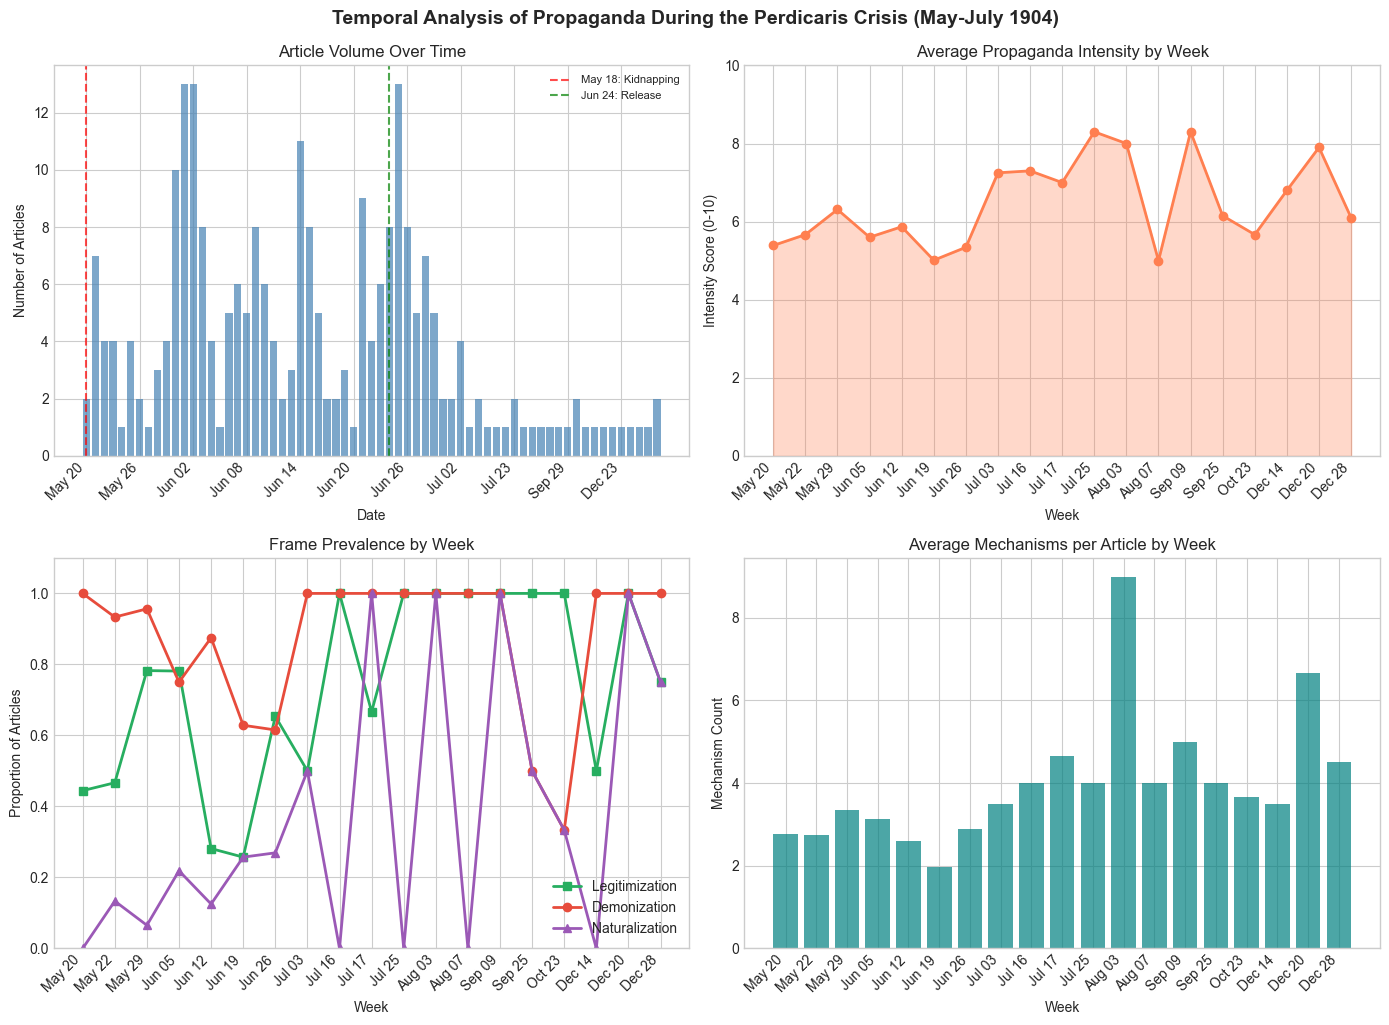


📅 COVERAGE BY PHASE

Before kidnapping (< May 18): No articles

During crisis (May 18 - Jun 24):
  Articles: 179
  Propaganda: 162 (90.5%)
  Avg Intensity: 5.79/10
  Frames: L=55% | D=85% | N=14%

After release (> Jun 24):
  Articles: 72
  Propaganda: 59 (81.9%)
  Avg Intensity: 5.85/10
  Frames: L=66% | D=71% | N=42%


In [ ]:
# ═══════════════════════════════════════════════════════════════════
# TEMPORAL ANALYSIS (FIXED) - Timezone-aware dates
# ═══════════════════════════════════════════════════════════════════

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Prepare data - ensure proper date parsing
df['date'] = pd.to_datetime(df['date'], errors='coerce')

# Check what we have
print("Date dtype:", df['date'].dtype)
print("Raw date range:", df['date'].min(), "to", df['date'].max())

# ═══════════════════════════════════════════════════════════════════
# FILTER TO 1904 ONLY (the Perdicaris Affair period)
# ═══════════════════════════════════════════════════════════════════
df_1904 = df[(df['date'].dt.year == 1904) & (df['date'].notna())].copy()
df_prop = df_1904[df_1904['isPropaganda'] == True].copy()

print(f"\n✓ Filtered to 1904: {len(df_1904)} articles ({len(df_prop)} with propaganda)")

# ═══════════════════════════════════════════════════════════════════
# KEY FIX: Make reference dates timezone-aware (UTC) to match data
# ═══════════════════════════════════════════════════════════════════
kidnapping_date = pd.Timestamp('1904-05-18', tz='UTC')
release_date = pd.Timestamp('1904-06-24', tz='UTC')

print(f"Date range: {df_1904['date'].min()} to {df_1904['date'].max()}")

# ─────────────────────────────────────────────────────────────────
# 1a. Article volume by DATE
# ─────────────────────────────────────────────────────────────────
daily_counts = df_1904.groupby(df_1904['date'].dt.strftime('%Y-%m-%d')).size()
daily_counts.index = pd.to_datetime(daily_counts.index)
daily_counts = daily_counts.sort_index()

axes[0, 0].bar(range(len(daily_counts)), daily_counts.values, color='steelblue', alpha=0.7)
axes[0, 0].set_title('Article Volume Over Time')
axes[0, 0].set_xlabel('Date')
axes[0, 0].set_ylabel('Number of Articles')

# Set x-ticks to show ~10 dates
tick_interval = max(1, len(daily_counts) // 10)
tick_positions = list(range(0, len(daily_counts), tick_interval))
tick_labels = [daily_counts.index[i].strftime('%b %d') for i in tick_positions if i < len(daily_counts)]
axes[0, 0].set_xticks(tick_positions[:len(tick_labels)])
axes[0, 0].set_xticklabels(tick_labels, rotation=45, ha='right')

# Mark key events (approximate positions)
dates_list = list(daily_counts.index)
for ref_date, label, color in [
    (pd.Timestamp('1904-05-18'), 'May 18: Kidnapping', 'red'),
    (pd.Timestamp('1904-06-24'), 'Jun 24: Release', 'green')
]:
    # Find closest date in our data
    closest_idx = None
    for i, d in enumerate(dates_list):
        if d >= ref_date:
            closest_idx = i
            break
    if closest_idx is not None:
        axes[0, 0].axvline(x=closest_idx, color=color, linestyle='--', alpha=0.7, label=label)

axes[0, 0].legend(fontsize=8, loc='upper right')

# ─────────────────────────────────────────────────────────────────
# 1b. Intensity over time (weekly average)
# ─────────────────────────────────────────────────────────────────
df_prop['week_label'] = df_prop['date'].dt.strftime('%Y-W%U')
weekly_intensity = df_prop.groupby('week_label')['intensity'].mean().sort_index()

axes[0, 1].plot(range(len(weekly_intensity)), weekly_intensity.values, marker='o', linewidth=2, color='coral')
axes[0, 1].fill_between(range(len(weekly_intensity)), weekly_intensity.values, alpha=0.3, color='coral')
axes[0, 1].set_title('Average Propaganda Intensity by Week')
axes[0, 1].set_xlabel('Week')
axes[0, 1].set_ylabel('Intensity Score (0-10)')
axes[0, 1].set_ylim(0, 10)

# Create readable week labels
week_dates = df_prop.groupby('week_label')['date'].min().sort_index()
week_labels = [pd.Timestamp(d).strftime('%b %d') for d in week_dates.values]
axes[0, 1].set_xticks(range(len(weekly_intensity)))
axes[0, 1].set_xticklabels(week_labels, rotation=45, ha='right')

# ─────────────────────────────────────────────────────────────────
# 1c. Frame prevalence over time (weekly)
# ─────────────────────────────────────────────────────────────────
frame_weekly = df_prop.groupby('week_label')[
    ['frame_legitimization', 'frame_demonization', 'frame_naturalization']
].mean().sort_index()

x = range(len(frame_weekly))
axes[1, 0].plot(x, frame_weekly['frame_legitimization'], marker='s', label='Legitimization', color='#27ae60', linewidth=2)
axes[1, 0].plot(x, frame_weekly['frame_demonization'], marker='o', label='Demonization', color='#e74c3c', linewidth=2)
axes[1, 0].plot(x, frame_weekly['frame_naturalization'], marker='^', label='Naturalization', color='#9b59b6', linewidth=2)
axes[1, 0].set_title('Frame Prevalence by Week')
axes[1, 0].set_xlabel('Week')
axes[1, 0].set_ylabel('Proportion of Articles')
axes[1, 0].legend(loc='lower right')
axes[1, 0].set_ylim(0, 1.1)
axes[1, 0].set_xticks(x)
axes[1, 0].set_xticklabels(week_labels, rotation=45, ha='right')

# ─────────────────────────────────────────────────────────────────
# 1d. Mechanism count over time (weekly)
# ─────────────────────────────────────────────────────────────────
weekly_mechs = df_prop.groupby('week_label')['strategiesCount'].mean().sort_index()

axes[1, 1].bar(range(len(weekly_mechs)), weekly_mechs.values, color='teal', alpha=0.7)
axes[1, 1].set_title('Average Mechanisms per Article by Week')
axes[1, 1].set_xlabel('Week')
axes[1, 1].set_ylabel('Mechanism Count')
axes[1, 1].set_xticks(range(len(weekly_mechs)))
axes[1, 1].set_xticklabels(week_labels, rotation=45, ha='right')

plt.tight_layout()
plt.suptitle('Temporal Analysis of Propaganda During the Perdicaris Crisis (May-July 1904)',
             y=1.02, fontsize=14, fontweight='bold')
plt.show()

# ─────────────────────────────────────────────────────────────────
# Summary table by phase
# ─────────────────────────────────────────────────────────────────
print("\n" + "="*60)
print("📅 COVERAGE BY PHASE")
print("="*60)

# FIX: Use timezone-aware dates for comparison
before_kidnapping = df_1904[df_1904['date'] < kidnapping_date]
during_crisis = df_1904[(df_1904['date'] >= kidnapping_date) & (df_1904['date'] <= release_date)]
after_release = df_1904[df_1904['date'] > release_date]

phases = [
    ("Before kidnapping (< May 18)", before_kidnapping),
    ("During crisis (May 18 - Jun 24)", during_crisis),
    ("After release (> Jun 24)", after_release)
]

for phase_name, data in phases:
    total = len(data)
    if total == 0:
        print(f"\n{phase_name}: No articles")
        continue
    prop_data = data[data['isPropaganda'] == True]
    prop_count = len(prop_data)
    avg_intensity = prop_data['intensity'].mean() if len(prop_data) > 0 else 0

    print(f"\n{phase_name}:")
    print(f"  Articles: {total}")
    print(f"  Propaganda: {prop_count} ({100*prop_count/total:.1f}%)")
    if len(prop_data) > 0:
        print(f"  Avg Intensity: {avg_intensity:.2f}/10")
        print(f"  Frames: L={prop_data['frame_legitimization'].mean()*100:.0f}% | D={prop_data['frame_demonization'].mean()*100:.0f}% | N={prop_data['frame_naturalization'].mean()*100:.0f}%")